# Lab 7: Radiometry and Image Formation

**Computer Vision & Image Processing**  
*M.Tech Laboratory Investigation*

---

### Overview & Roadmap
This laboratory explores the physical principles governing how light propagates, interacts with surfaces, passes through camera optics, and gets digitized into image pixels:
1. **PART A: Radiometric Modeling & Numerical Simulations**
   - **Q1:** Received Illumination vs. Surface Area & Distance (Inverse-Square Law).
   - **Q2:** Sensitivity Analysis of Illumination Power, Distance, Surface Orientation ($\cos\theta$), and Reflectance ($\rho$).
   - **Q3:** Surface Reflection Modeling: Lambertian Diffuse vs. Phong Specular/Glossy.
   - **Q4:** Diffuse Radiance Dynamics & Lightness Constancy Ambiguity ($L_o = \frac{\rho}{\pi} E_i$).
   - **Q5:** Simplified Camera Radiometry: Aperture ($f$-number), Exposure Time, Focal Length, and $\cos^4\alpha$ Natural Vignetting.
   - **Q6:** End-to-End Image Formation Simulation Pipeline (Source $\to$ Surface $\to$ Lens $\to$ Sensor).
   - **Q7:** Synthetic 3D Multi-Object Scene Rendering under Diverse Lighting Conditions.

2. **PART B: Experimental Investigation on Real Physical Captures**
   - Quantitative & qualitative analysis of physical laboratory captures under direct vs. shadowed illumination.
   - Comparative evaluation across: (a) Overall Brightness, (b) Pixel Distributions, (c) Statistical Moments (Mean & Std), (d) Regional Variations (ROIs), and (e) Visible Appearance Changes.

> **Theoretical Companion:**  
> Complete theoretical derivations, radiometric definitions, step-by-step logic, and experimental analyses are documented in [`walkthrough.md`](walkthrough.md).


In [1]:
# 0. Setup and Core Libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import stats

# Set high-quality visualization defaults
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.dpi': 120
})

print("Environment initialized successfully. Ready for radiometry experiments.")


Environment initialized successfully. Ready for radiometry experiments.


## 1. Received Illumination vs. Surface Area and Distance (Question 1)

**Mathematical Formulation:**
- **Irradiance ($E$):** Incident flux per unit area from an isotropic source of radiant intensity $I$ [W/sr]:
  $$E(r) = \frac{\Phi_{rec}}{A} = \frac{I}{r^2} \quad [\text{W/m}^2]$$
- **Total Received Radiant Flux ($\Phi_{rec}$):** Power intercepted by a surface patch of area $A$:
  $$\Phi_{rec}(r, A) = E(r) \cdot A = \frac{I \cdot A}{r^2} \quad [\text{W}]$$
- **Key Insight:** Local irradiance $E$ is *independent of area* and follows the pure **Inverse-Square Law** ($1/r^2$). Total received flux $\Phi_{rec}$ scales *linearly with area* and inversely with distance squared.


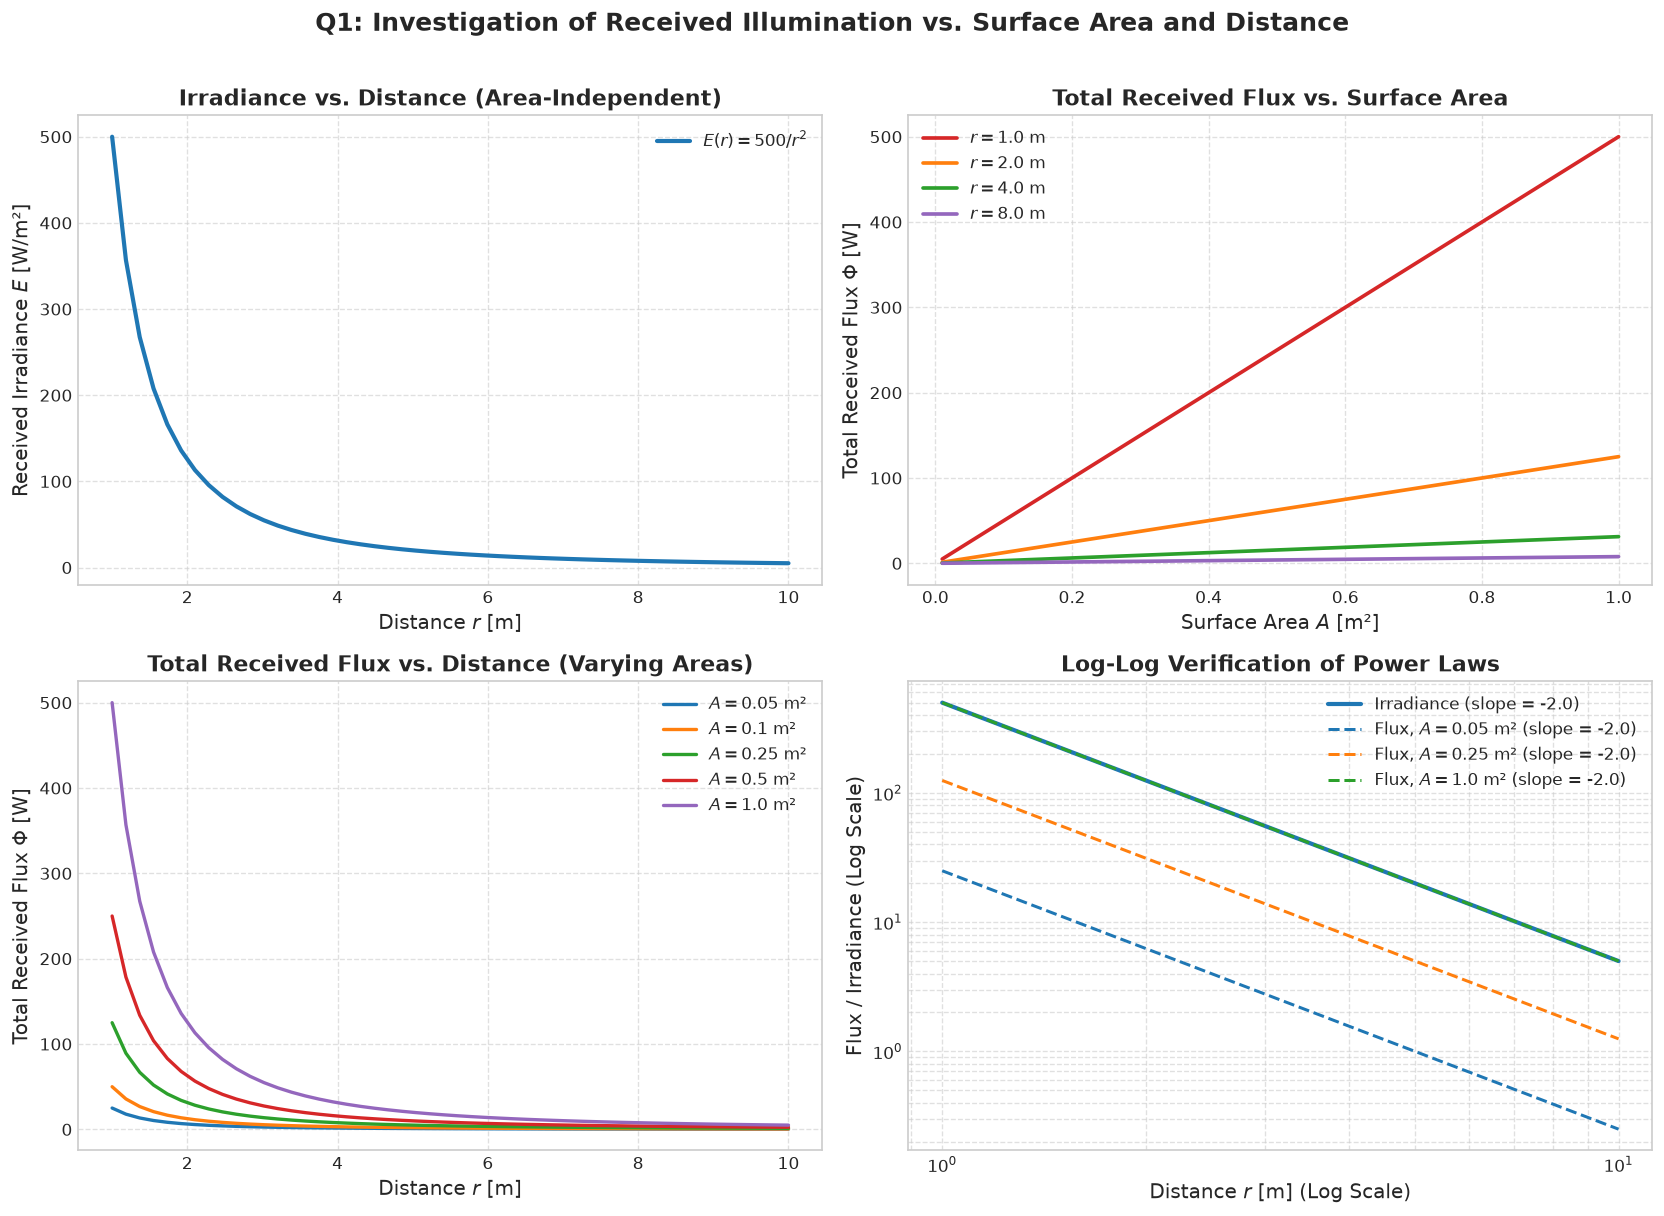

In [2]:
# 1. Received Illumination vs. Surface Area & Distance
I_source = 500.0  # Radiant intensity of point source (W/sr)

# Sample parametric space
distances = np.linspace(1.0, 10.0, 50)              # Distance r in [1m, 10m]
areas = np.array([0.05, 0.10, 0.25, 0.50, 1.00])    # Surface areas in m^2

# Compute irradiance and total flux matrix
irradiance = I_source / (distances ** 2)
flux_matrix = np.outer(areas, irradiance)

# Visualizations: 4-Panel Analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Irradiance vs Distance (Inverse-Square Law)
axes[0, 0].plot(distances, irradiance, color='#1f77b4', lw=2.5, label=r'$E(r) = 500 / r^2$')
axes[0, 0].set_title('Irradiance vs. Distance (Area-Independent)', fontweight='bold')
axes[0, 0].set_xlabel('Distance $r$ [m]')
axes[0, 0].set_ylabel('Received Irradiance $E$ [W/m²]')
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
axes[0, 0].legend()

# Subplot 2: Total Received Flux vs Surface Area (Linearity)
fixed_dists = [1.0, 2.0, 4.0, 8.0]
area_sweep = np.linspace(0.01, 1.0, 50)
palette = ['#d62728', '#ff7f0e', '#2ca02c', '#9467bd']
for dist, col in zip(fixed_dists, palette):
    flux_vs_area = (I_source * area_sweep) / (dist ** 2)
    axes[0, 1].plot(area_sweep, flux_vs_area, lw=2.2, color=col, label=f'$r = {dist}$ m')
axes[0, 1].set_title('Total Received Flux vs. Surface Area', fontweight='bold')
axes[0, 1].set_xlabel('Surface Area $A$ [m²]')
axes[0, 1].set_ylabel(r'Total Received Flux $\Phi$ [W]')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend()

# Subplot 3: Total Flux vs Distance for Multiple Surface Areas
for i, A in enumerate(areas):
    axes[1, 0].plot(distances, flux_matrix[i, :], lw=2.0, label=f'$A = {A}$ m²')
axes[1, 0].set_title('Total Received Flux vs. Distance (Varying Areas)', fontweight='bold')
axes[1, 0].set_xlabel('Distance $r$ [m]')
axes[1, 0].set_ylabel(r'Total Received Flux $\Phi$ [W]')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend()

# Subplot 4: Log-Log Verification of Theoretical Exponents
axes[1, 1].loglog(distances, irradiance, color='#1f77b4', lw=2.5, label='Irradiance (slope = -2.0)')
for i in [0, 2, 4]:
    axes[1, 1].loglog(distances, flux_matrix[i, :], linestyle='--', lw=1.8, label=f'Flux, $A={areas[i]}$ m² (slope = -2.0)')
axes[1, 1].set_title('Log-Log Verification of Power Laws', fontweight='bold')
axes[1, 1].set_xlabel('Distance $r$ [m] (Log Scale)')
axes[1, 1].set_ylabel('Flux / Irradiance (Log Scale)')
axes[1, 1].grid(True, which='both', linestyle='--', alpha=0.6)
axes[1, 1].legend()

plt.suptitle('Q1: Investigation of Received Illumination vs. Surface Area and Distance', y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Numerical Experiment on Illumination Power, Distance, Surface Orientation, and Surface Properties (Question 2)

**Physical Model:**
- An isotropic emitter of power $P$ [W] illuminates a surface patch with reflectance $\rho$ at distance $r$ [m] and surface tilt $\theta$:
  $$L(P, r, \theta, \rho) = \frac{\rho}{\pi} E = \frac{\rho P \cos\theta}{4\pi^2 r^2} \quad [\text{W}/(\text{m}^2\cdot\text{sr})]$$
- **Baseline Parameters:**
  - Illumination Power: $P_0 = 100.0$ W
  - Distance: $r_0 = 2.0$ m
  - Surface Orientation: $\theta_0 = 0^\circ$ ($\cos\theta_0 = 1.0$)
  - Surface Reflectance: $\rho_0 = 0.8$
  - Baseline Reflected Radiance: $L_0 = \frac{0.8 \times 100}{4\pi^2 \times 2.0^2} \approx 0.5066 \, \text{W}/(\text{m}^2\cdot\text{sr})$
- **One-at-a-Time (OAT) Sensitivity Analysis:** Vary each parameter individually while freezing the remaining three at baseline.


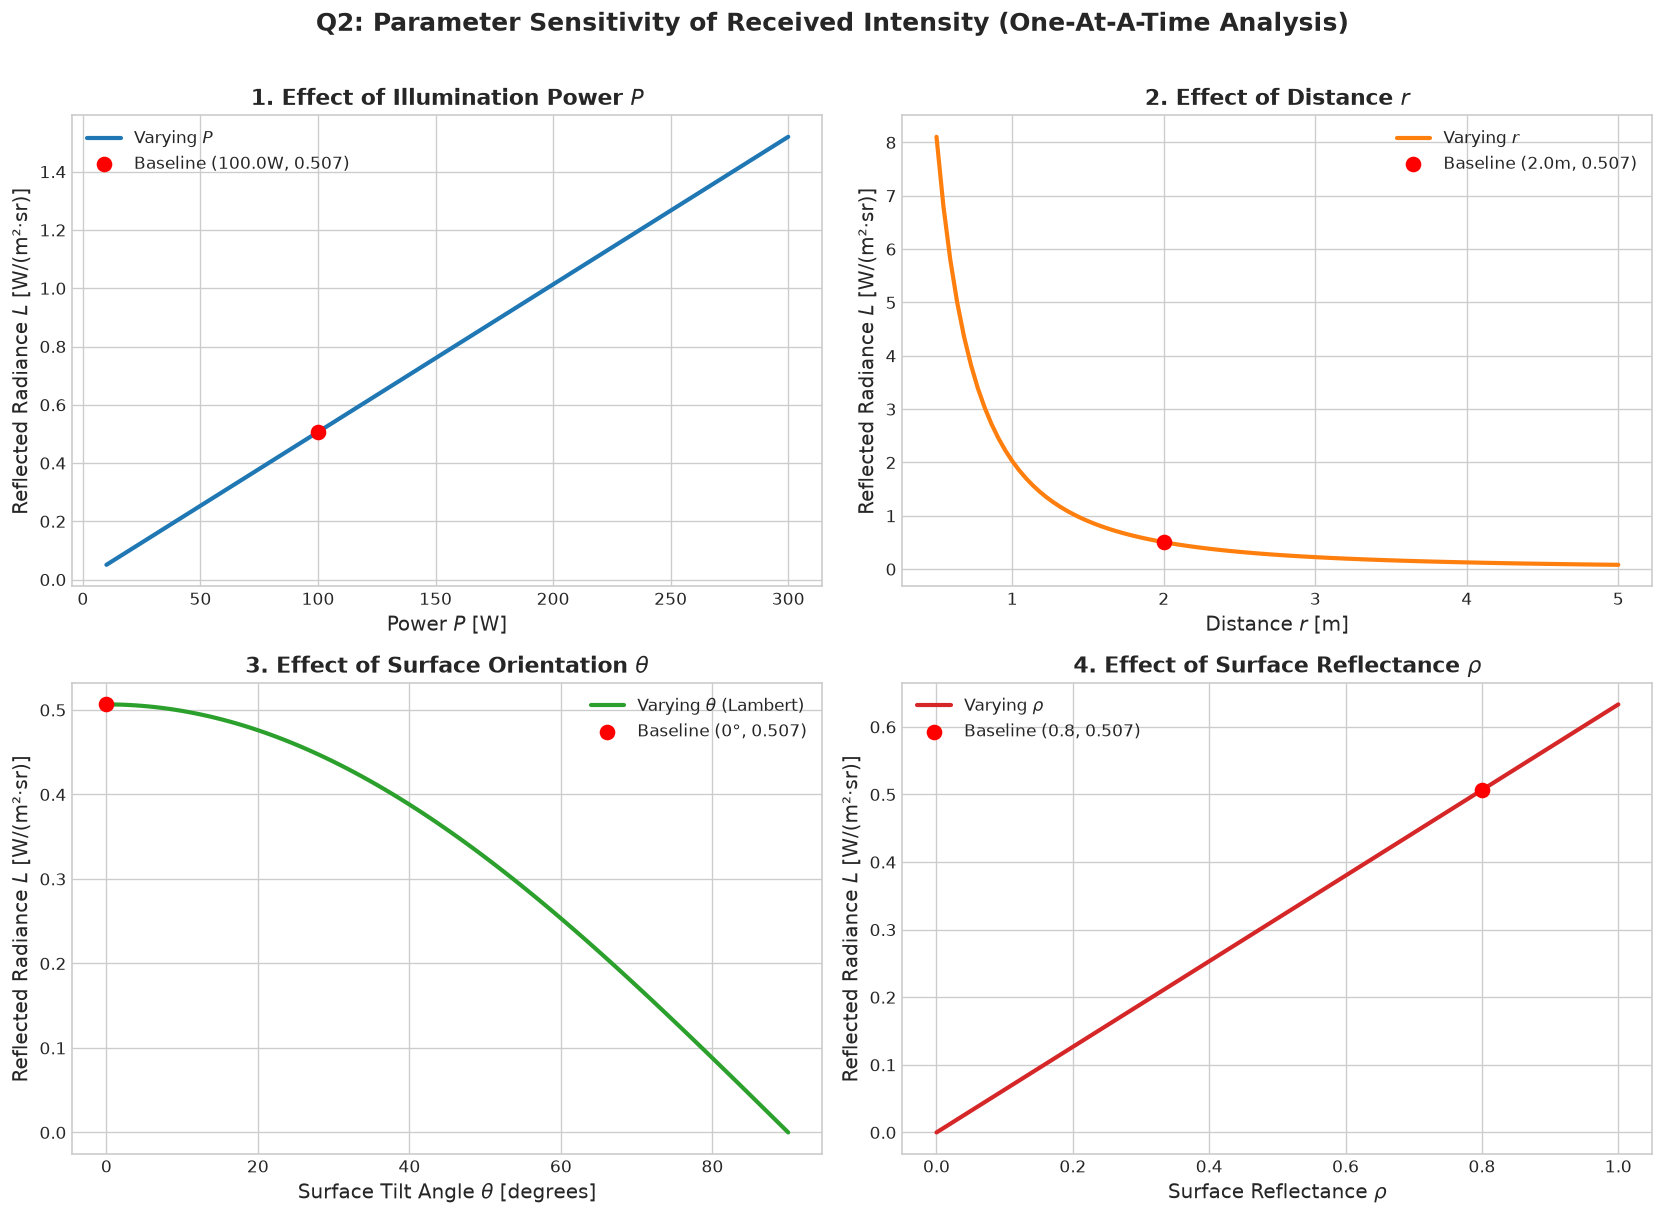

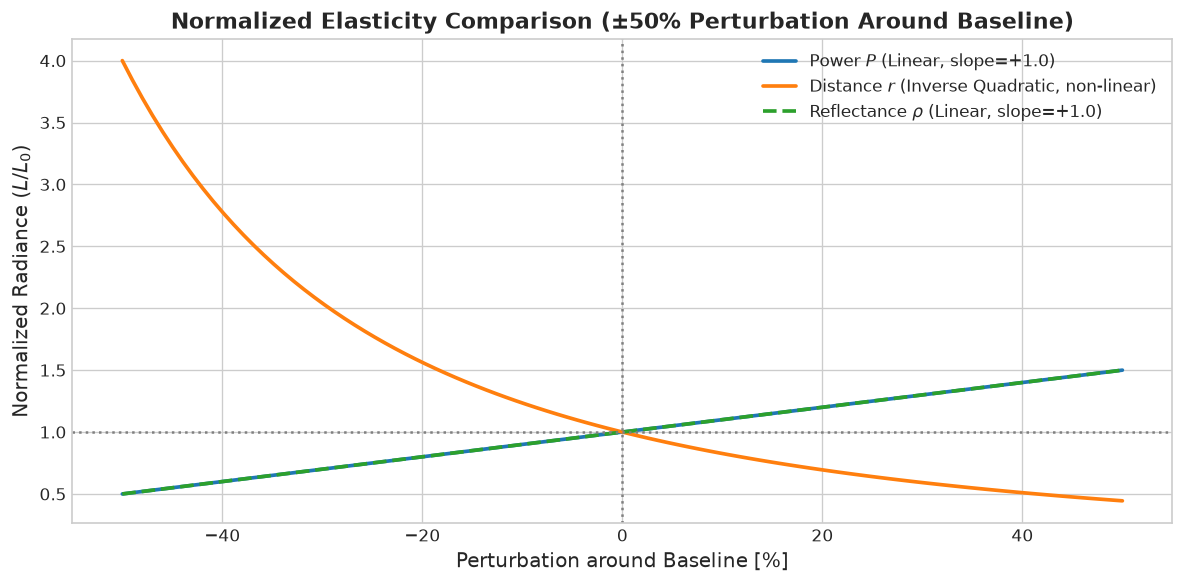

In [3]:
# 2. Numerical Sensitivity Experiment (One-At-A-Time Analysis)
P0 = 100.0   # Baseline power (W)
r0 = 2.0     # Baseline distance (m)
theta0 = 0.0 # Baseline orientation (rad)
rho0 = 0.8   # Baseline reflectance

def calc_radiance(P, r, theta, rho):
    cos_t = np.maximum(0.0, np.cos(theta))
    return (rho * P * cos_t) / (4.0 * (np.pi ** 2) * (r ** 2))

L0 = calc_radiance(P0, r0, theta0, rho0)

# Parameter Ranges
P_range = np.linspace(10.0, 300.0, 100)
r_range = np.linspace(0.5, 5.0, 100)
theta_deg = np.linspace(0.0, 90.0, 100)
theta_range = np.radians(theta_deg)
rho_range = np.linspace(0.0, 1.0, 100)

# Calculate responses
L_P = calc_radiance(P_range, r0, theta0, rho0)
L_r = calc_radiance(P0, r_range, theta0, rho0)
L_theta = calc_radiance(P0, r0, theta_range, rho0)
L_rho = calc_radiance(P0, r0, theta0, rho_range)

# Multi-panel visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Power Variation
axes[0, 0].plot(P_range, L_P, color='#1f77b4', lw=2.5, label='Varying $P$')
axes[0, 0].scatter([P0], [L0], color='red', s=70, zorder=5, label=f'Baseline ({P0}W, {L0:.3f})')
axes[0, 0].set_title('1. Effect of Illumination Power $P$', fontweight='bold')
axes[0, 0].set_xlabel('Power $P$ [W]')
axes[0, 0].set_ylabel('Reflected Radiance $L$ [W/(m²·sr)]')
axes[0, 0].legend()

# Subplot 2: Distance Variation
axes[0, 1].plot(r_range, L_r, color='#ff7f0e', lw=2.5, label='Varying $r$')
axes[0, 1].scatter([r0], [L0], color='red', s=70, zorder=5, label=f'Baseline ({r0}m, {L0:.3f})')
axes[0, 1].set_title('2. Effect of Distance $r$', fontweight='bold')
axes[0, 1].set_xlabel('Distance $r$ [m]')
axes[0, 1].set_ylabel('Reflected Radiance $L$ [W/(m²·sr)]')
axes[0, 1].legend()

# Subplot 3: Surface Orientation Variation (Cosine Law)
axes[1, 0].plot(theta_deg, L_theta, color='#2ca02c', lw=2.5, label=r'Varying $\theta$ (Lambert)')
axes[1, 0].scatter([np.degrees(theta0)], [L0], color='red', s=70, zorder=5, label=f'Baseline (0°, {L0:.3f})')
axes[1, 0].set_title(r'3. Effect of Surface Orientation $\theta$', fontweight='bold')
axes[1, 0].set_xlabel(r'Surface Tilt Angle $\theta$ [degrees]')
axes[1, 0].set_ylabel('Reflected Radiance $L$ [W/(m²·sr)]')
axes[1, 0].legend()

# Subplot 4: Surface Reflectance Variation
axes[1, 1].plot(rho_range, L_rho, color='#d62728', lw=2.5, label=r'Varying $\rho$')
axes[1, 1].scatter([rho0], [L0], color='red', s=70, zorder=5, label=f'Baseline ({rho0}, {L0:.3f})')
axes[1, 1].set_title(r'4. Effect of Surface Reflectance $\rho$', fontweight='bold')
axes[1, 1].set_xlabel(r'Surface Reflectance $\rho$')
axes[1, 1].set_ylabel('Reflected Radiance $L$ [W/(m²·sr)]')
axes[1, 1].legend()

plt.suptitle('Q2: Parameter Sensitivity of Received Intensity (One-At-A-Time Analysis)', y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Normalized sensitivity comparison (Relative % change around baseline)
delta_pct = np.linspace(-0.5, 0.5, 100) # +/- 50% relative change
L_norm_P = calc_radiance(P0 * (1 + delta_pct), r0, theta0, rho0) / L0
L_norm_r = calc_radiance(P0, r0 * (1 + delta_pct), theta0, rho0) / L0
L_norm_rho = calc_radiance(P0, r0, theta0, rho0 * (1 + delta_pct)) / L0

plt.figure(figsize=(10, 5))
plt.plot(delta_pct * 100, L_norm_P, lw=2.2, label='Power $P$ (Linear, slope=+1.0)')
plt.plot(delta_pct * 100, L_norm_r, lw=2.2, label='Distance $r$ (Inverse Quadratic, non-linear)')
plt.plot(delta_pct * 100, L_norm_rho, lw=2.2, linestyle='--', label=r'Reflectance $\rho$ (Linear, slope=+1.0)')
plt.axvline(0, color='gray', linestyle=':')
plt.axhline(1, color='gray', linestyle=':')
plt.title('Normalized Elasticity Comparison (±50% Perturbation Around Baseline)', fontweight='bold')
plt.xlabel('Perturbation around Baseline [%]')
plt.ylabel('Normalized Radiance ($L / L_0$)')
plt.legend()
plt.tight_layout()
plt.show()


## 3. Simulating Two Surfaces with Different Reflection Characteristics (Question 3)

**Bidirectional Reflectance Distribution Function (BRDF):**
- **Surface 1: Ideal Lambertian Diffuse (Matte Surface)**
  - BRDF: $f_{r, \text{diff}} = \frac{k_d}{\pi}$
  - Reflected Radiance: $L_{\text{diff}} = \frac{k_d}{\pi} E_i \max(0, \mathbf{n} \cdot \mathbf{l})$
  - *Key Property:* Radiance is **independent of viewing angle** $\mathbf{v}$. A diffuse surface appears equally bright from all view angles.
- **Surface 2: Glossy / Specular Surface (Phong Model)**
  - BRDF: $f_{r, \text{gloss}} = \frac{k_d}{\pi} + k_s \frac{\max(0, \mathbf{r} \cdot \mathbf{v})^\alpha}{\mathbf{n} \cdot \mathbf{l}}$
  - Reflected Radiance: $L_{\text{gloss}} = \frac{k_d}{\pi} E_i \max(0, \mathbf{n} \cdot \mathbf{l}) + k_s E_i \max(0, \mathbf{r} \cdot \mathbf{v})^\alpha$
  - Where $\mathbf{r} = 2(\mathbf{n} \cdot \mathbf{l})\mathbf{n} - \mathbf{l}$ is the ideal specular reflection vector, and $\alpha$ is the specular shininess exponent.
  - *Key Property:* Highly **viewpoint-dependent**. A bright specular highlight occurs when the view vector aligns with the reflection vector ($\mathbf{v} \approx \mathbf{r}$).


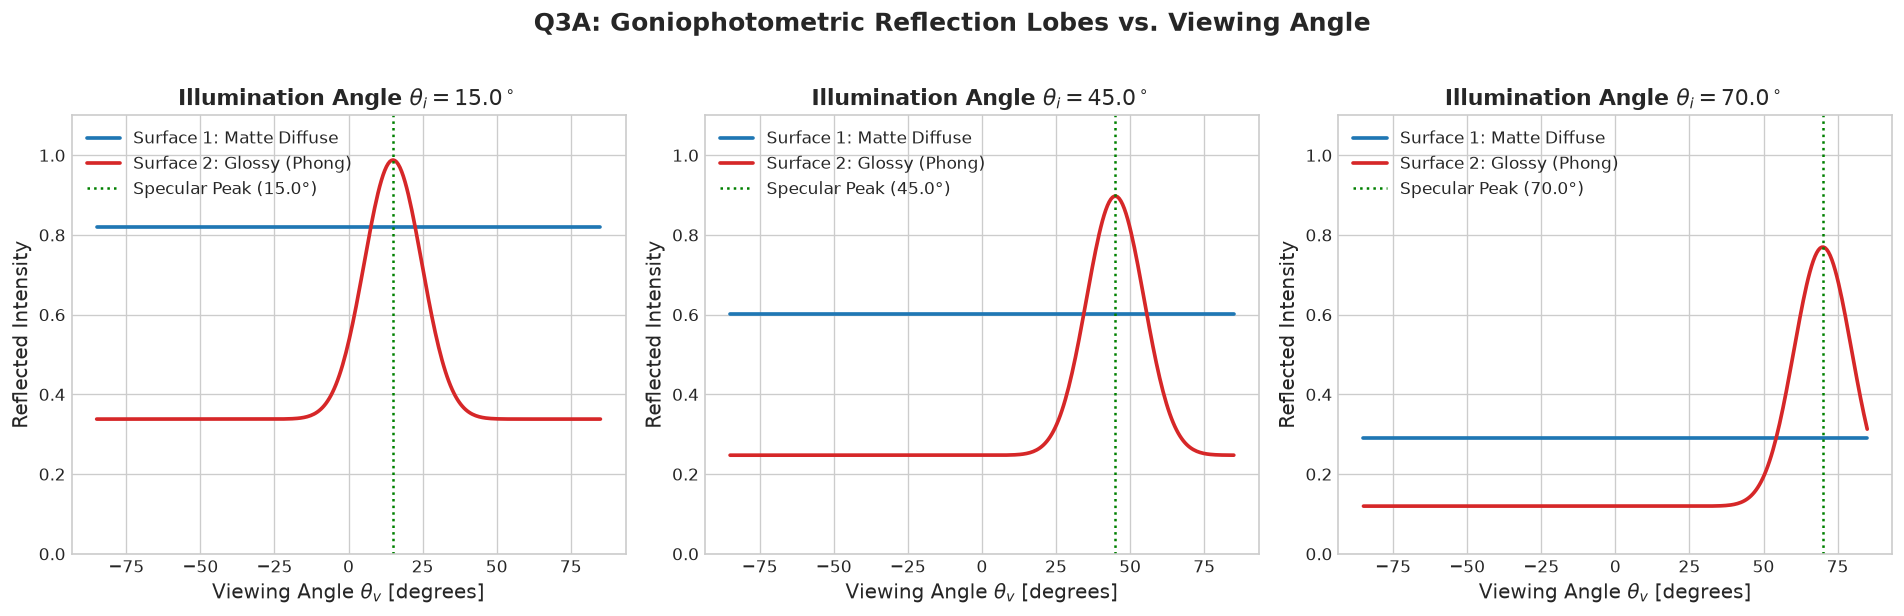

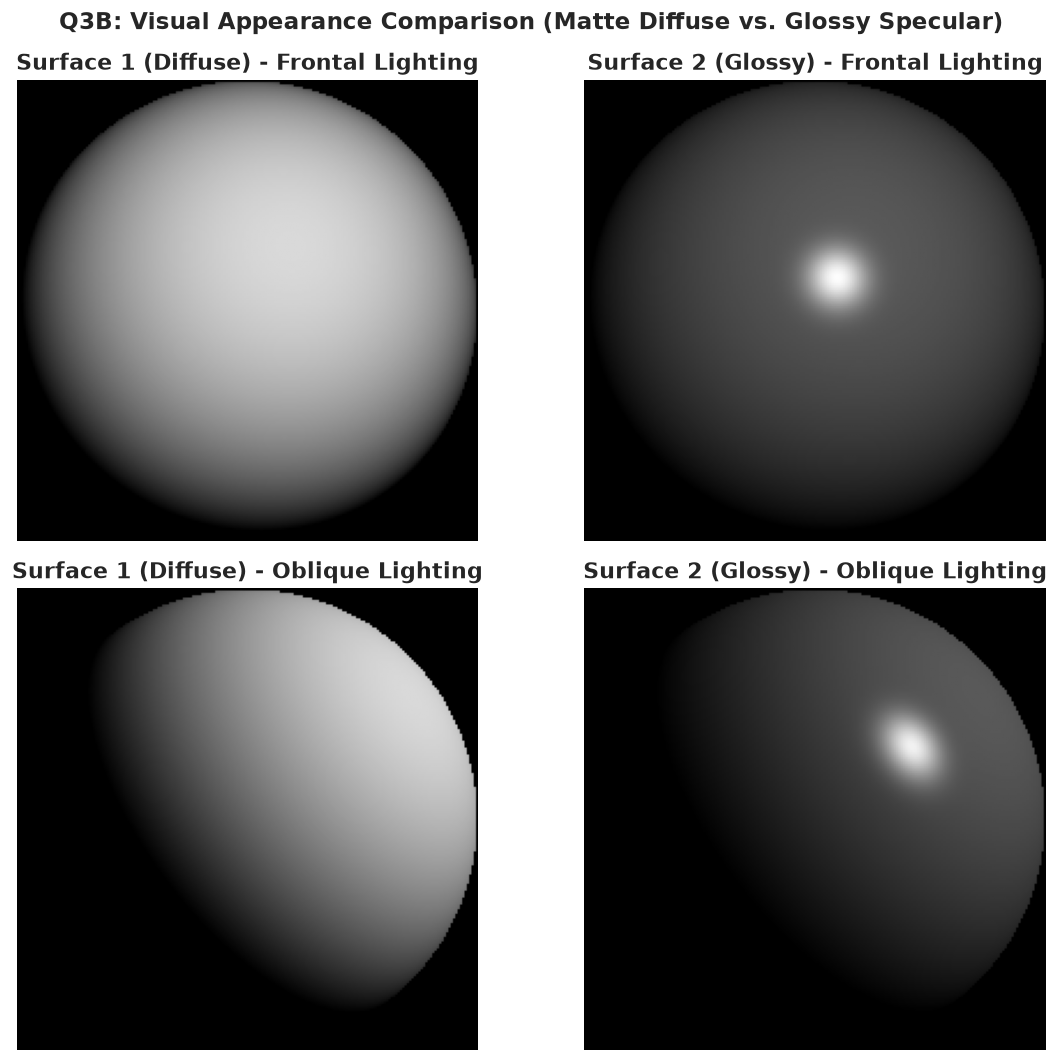

In [4]:
# 3. Two Surfaces with Different Reflection Characteristics
# Goniophotometric polar lobes and 3D visual rendering

# 3A. Goniophotometric Profiles (Viewing Angle Variation)
theta_v_deg = np.linspace(-85, 85, 300)
theta_v = np.radians(theta_v_deg)

# Surface properties
kd_diff = 0.85; ks_diff = 0.0
kd_gloss = 0.35; ks_gloss = 0.65; alpha = 35

light_incidents = [15.0, 45.0, 70.0] # Incident lighting angles (deg)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, ti_deg in enumerate(light_incidents):
    ti = np.radians(ti_deg)
    cos_i = np.cos(ti)
    
    # Diffuse response (flat across viewing angle)
    L_diffuse = kd_diff * cos_i * np.ones_like(theta_v)
    
    # Specular reflection angle is at theta_v = ti
    cos_rv = np.maximum(0.0, np.cos(theta_v - ti))
    L_glossy = kd_gloss * cos_i + ks_gloss * (cos_rv ** alpha)
    
    axes[idx].plot(theta_v_deg, L_diffuse, color='#1f77b4', lw=2.2, label='Surface 1: Matte Diffuse')
    axes[idx].plot(theta_v_deg, L_glossy, color='#d62728', lw=2.2, label='Surface 2: Glossy (Phong)')
    axes[idx].axvline(ti_deg, color='green', linestyle=':', label=f'Specular Peak ({ti_deg}°)')
    axes[idx].set_title(fr'Illumination Angle $\theta_i = {ti_deg}^\circ$', fontweight='bold')
    axes[idx].set_xlabel(r'Viewing Angle $\theta_v$ [degrees]')
    axes[idx].set_ylabel('Reflected Intensity')
    axes[idx].set_ylim(0, 1.1)
    axes[idx].legend(loc='upper left')

plt.suptitle('Q3A: Goniophotometric Reflection Lobes vs. Viewing Angle', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# 3B. Visual Appearance Rendering of 3D Spheres
def render_sphere_appearance(kd, ks, alpha, light_dir, res=200):
    Y, X = np.ogrid[-1:1:res*1j, -1:1:res*1j]
    R2 = X**2 + Y**2
    mask = R2 <= 1.0
    Z = np.sqrt(np.maximum(0.0, 1.0 - R2))
    
    N = np.zeros((res, res, 3))
    N[:, :, 0] = X * mask
    N[:, :, 1] = -Y * mask
    N[:, :, 2] = Z * mask
    
    L = light_dir / np.linalg.norm(light_dir)
    V = np.array([0.0, 0.0, 1.0])
    
    N_dot_L = np.maximum(0.0, np.sum(N * L, axis=-1))
    R = 2.0 * N_dot_L[:, :, None] * N - L
    R_dot_V = np.maximum(0.0, np.sum(R * V, axis=-1))
    spec = (R_dot_V ** alpha) * (N_dot_L > 0)
    
    img = (kd * N_dot_L + ks * spec) * mask
    return np.clip(img, 0.0, 1.0)

light_frontal = np.array([0.2, 0.3, 1.0])
light_oblique = np.array([0.8, 0.6, 0.5])

diff_frontal = render_sphere_appearance(0.85, 0.0, 1, light_frontal)
gloss_frontal = render_sphere_appearance(0.35, 0.65, 30, light_frontal)

diff_oblique = render_sphere_appearance(0.85, 0.0, 1, light_oblique)
gloss_oblique = render_sphere_appearance(0.35, 0.65, 30, light_oblique)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes[0, 0].imshow(diff_frontal, cmap='gray', vmin=0, vmax=1)
axes[0, 0].set_title('Surface 1 (Diffuse) - Frontal Lighting', fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(gloss_frontal, cmap='gray', vmin=0, vmax=1)
axes[0, 1].set_title('Surface 2 (Glossy) - Frontal Lighting', fontweight='bold')
axes[0, 1].axis('off')

axes[1, 0].imshow(diff_oblique, cmap='gray', vmin=0, vmax=1)
axes[1, 0].set_title('Surface 1 (Diffuse) - Oblique Lighting', fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(gloss_oblique, cmap='gray', vmin=0, vmax=1)
axes[1, 1].set_title('Surface 2 (Glossy) - Oblique Lighting', fontweight='bold')
axes[1, 1].axis('off')

plt.suptitle('Q3B: Visual Appearance Comparison (Matte Diffuse vs. Glossy Specular)', y=0.98, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Diffuse Surface Outgoing Radiance Simulation (Question 4)

**Bilinear Radiometric Formulation:**
- For an ideal Lambertian surface, the outgoing reflected radiance $L_o$ is strictly determined by:
  $$L_o = \frac{\rho}{\pi} E_i \quad [\text{W}/(\text{m}^2\cdot\text{sr})]$$
- **Bilinear Sensitivity Derivatives:**
  $$\frac{\partial L_o}{\partial E_i} = \frac{\rho}{\pi}, \quad \frac{\partial L_o}{\partial \rho} = \frac{E_i}{\pi}, \quad \frac{\partial^2 L_o}{\partial E_i \partial \rho} = \frac{1}{\pi}$$
- **Lightness Constancy Ambiguity:**
  Because $L_o$ is the product of illumination $E_i$ and reflectance $\rho$, infinitely many combinations produce the *exact same* outgoing radiance (iso-radiance hyperbola: $\rho \cdot E_i = \text{constant}$). This is the fundamental ill-posed problem of lightness constancy in vision.


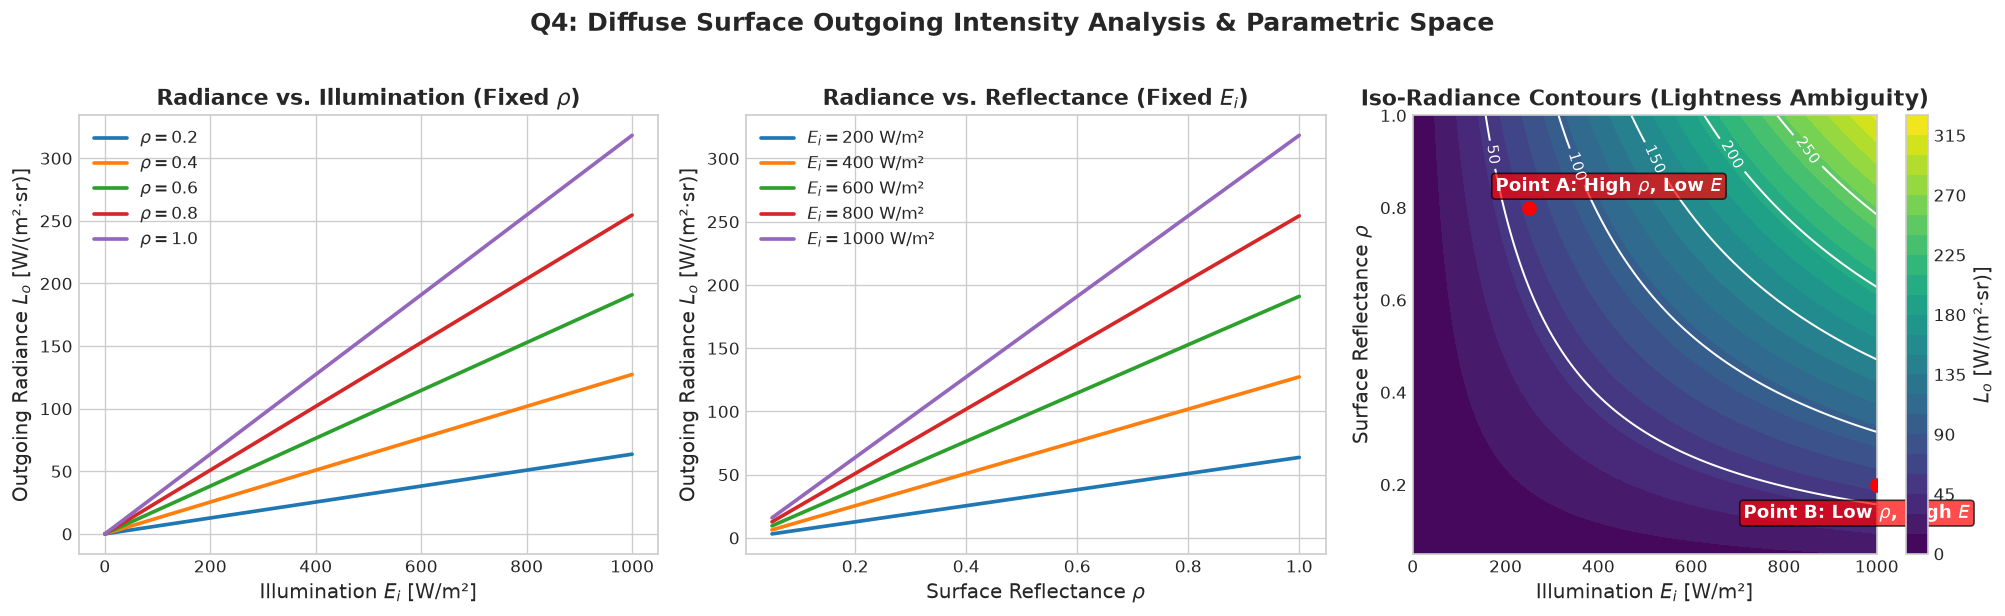

In [5]:
# 4. Outgoing Radiance of a Diffuse Surface vs Illumination & Reflectance
E_vals = np.linspace(0, 1000, 100)  # Incident illumination (W/m^2 or lux)
rho_vals = np.linspace(0.05, 1.0, 100) # Reflectance albedo

E_grid, rho_grid = np.meshgrid(E_vals, rho_vals)
Lo_grid = (rho_grid / np.pi) * E_grid

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Subplot 1: Outgoing Radiance vs Illumination for Fixed Reflectance
fixed_rhos = [0.2, 0.4, 0.6, 0.8, 1.0]
for r_val in fixed_rhos:
    axes[0].plot(E_vals, (r_val / np.pi) * E_vals, lw=2.2, label=fr'$\rho = {r_val}$')
axes[0].set_title(r'Radiance vs. Illumination (Fixed $\rho$)', fontweight='bold')
axes[0].set_xlabel('Illumination $E_i$ [W/m²]')
axes[0].set_ylabel('Outgoing Radiance $L_o$ [W/(m²·sr)]')
axes[0].legend()

# Subplot 2: Outgoing Radiance vs Reflectance for Fixed Illumination
fixed_Es = [200, 400, 600, 800, 1000]
for e_val in fixed_Es:
    axes[1].plot(rho_vals, (rho_vals / np.pi) * e_val, lw=2.2, label=fr'$E_i = {e_val}$ W/m²')
axes[1].set_title(r'Radiance vs. Reflectance (Fixed $E_i$)', fontweight='bold')
axes[1].set_xlabel(r'Surface Reflectance $\rho$')
axes[1].set_ylabel('Outgoing Radiance $L_o$ [W/(m²·sr)]')
axes[1].legend()

# Subplot 3: 2D Heatmap & Iso-Radiance Contours (Constancy Ambiguity)
cs = axes[2].contourf(E_grid, rho_grid, Lo_grid, levels=25, cmap='viridis')
cbar = fig.colorbar(cs, ax=axes[2])
cbar.set_label('$L_o$ [W/(m²·sr)]')
lines = axes[2].contour(E_grid, rho_grid, Lo_grid, levels=[50, 100, 150, 200, 250], colors='white', linewidths=1.2)
axes[2].clabel(lines, inline=True, fontsize=9, fmt='%1.0f')

# Highlight equivalence points along the Lo = 63.66 contour (rho * E = 200)
axes[2].scatter([250, 1000], [0.8, 0.2], color='red', s=60, zorder=6)
axes[2].annotate(r'Point A: High $\rho$, Low $E$', (250, 0.8), textcoords="offset points", xytext=(-20, 10),
                color='white', fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='red', alpha=0.7))
axes[2].annotate(r'Point B: Low $\rho$, High $E$', (1000, 0.2), textcoords="offset points", xytext=(-80, -20),
                color='white', fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='red', alpha=0.7))

axes[2].set_title('Iso-Radiance Contours (Lightness Ambiguity)', fontweight='bold')
axes[2].set_xlabel('Illumination $E_i$ [W/m²]')
axes[2].set_ylabel(r'Surface Reflectance $\rho$')

plt.suptitle('Q4: Diffuse Surface Outgoing Intensity Analysis & Parametric Space', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Simplified Camera Image-Formation Simulation (Question 5)

**Camera Radiometry (Horn's Fundamental Equation):**
- Scene radiance $L$ collected by a thin lens with focal length $f$ and aperture diameter $d$ ($f$-number $N = f/d$) produces image plane irradiance:
  $$E_{\text{img}} = L \cdot \frac{\pi}{4} \left(\frac{d}{f}\right)^2 \cos^4\alpha = \frac{\pi L}{4 N^2} \cos^4\alpha \quad [\text{W/m}^2]$$
  where $\alpha$ is the off-axis field angle (natural vignetting).
- **Sensor Exposure (Radiant Energy Density):**
  $$H = E_{\text{img}} \cdot \Delta t = \frac{\pi L \Delta t}{4 N^2} \cos^4\alpha \quad [\text{J/m}^2]$$
  where $\Delta t$ is the exposure shutter time [s].
- **Digital Quantization:**
  $$I_{\text{digital}} = \text{clip}\left(\text{round}\left(K \cdot H\right), 0, 255\right)$$


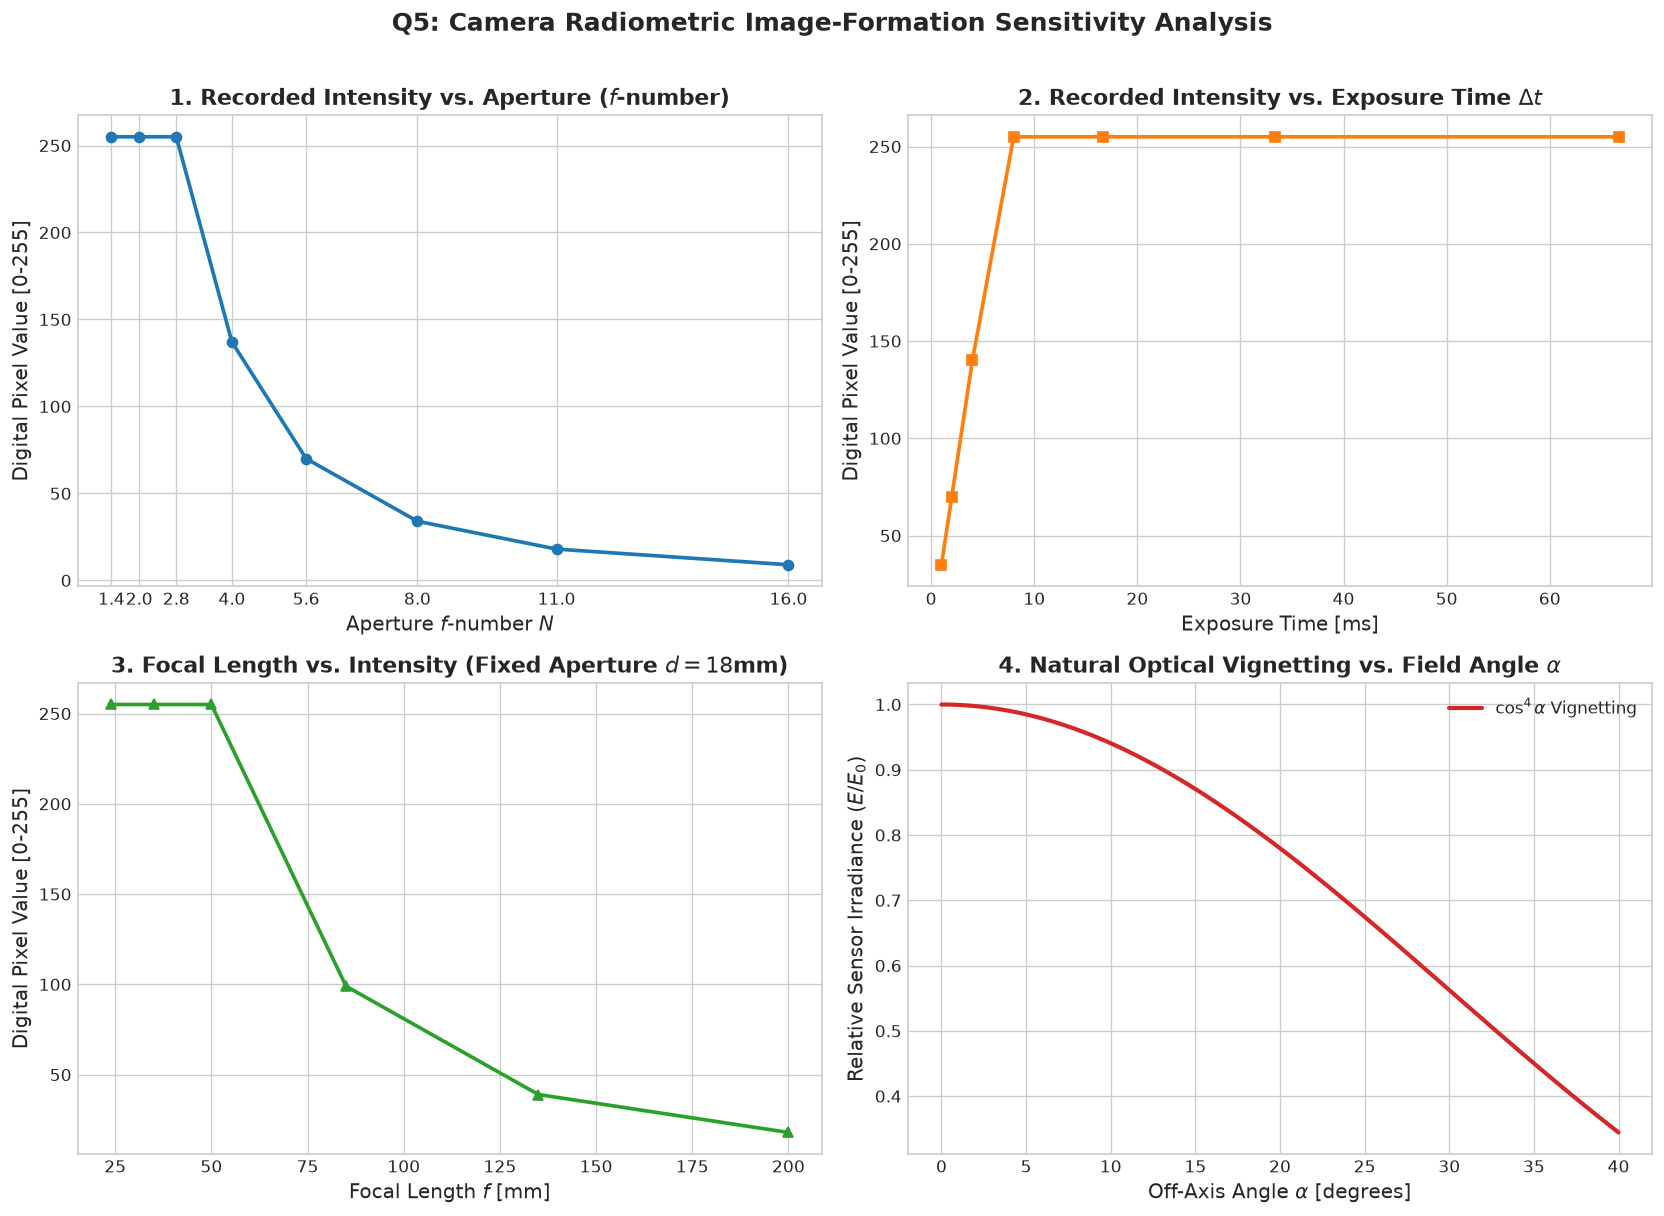

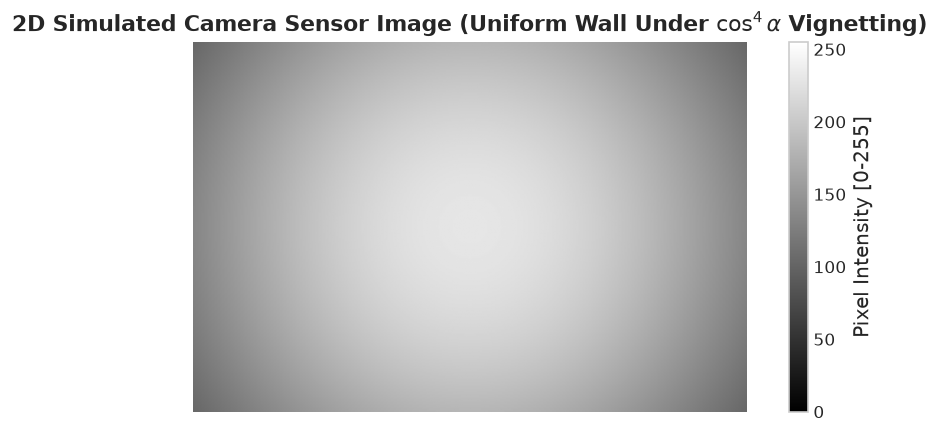

In [6]:
# 5. Camera Image-Formation Simulation: Aperture, Exposure, Focal Length, Vignetting
scene_L = 100.0  # Constant scene radiance (W/(m^2 sr))
K_gain = 3500.0  # Sensor analog-to-digital conversion factor

# 5A. Systematic Parameter Sweeps
f_stops = np.array([1.4, 2.0, 2.8, 4.0, 5.6, 8.0, 11.0, 16.0])
exp_times = np.array([1/1000, 1/500, 1/250, 1/125, 1/60, 1/30, 1/15])
focal_lengths_mm = np.array([24, 35, 50, 85, 135, 200]) # mm

# Fixed defaults
default_N = 2.8
default_dt = 1/125
default_f = 50.0

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Effect of Aperture f-number (1/N^2 falloff)
E_vs_N = (np.pi * scene_L) / (4.0 * (f_stops ** 2))
I_vs_N = np.clip(np.round(K_gain * E_vs_N * default_dt), 0, 255)
axes[0, 0].plot(f_stops, I_vs_N, 'o-', color='#1f77b4', lw=2.2)
axes[0, 0].set_title('1. Recorded Intensity vs. Aperture ($f$-number)', fontweight='bold')
axes[0, 0].set_xlabel('Aperture $f$-number $N$')
axes[0, 0].set_ylabel('Digital Pixel Value [0-255]')
axes[0, 0].set_xticks(f_stops)

# Subplot 2: Effect of Exposure Time (Linear scaling)
H_vs_dt = ((np.pi * scene_L) / (4.0 * (default_N ** 2))) * exp_times
I_vs_dt = np.clip(np.round(K_gain * H_vs_dt), 0, 255)
axes[0, 1].plot(exp_times * 1000, I_vs_dt, 's-', color='#ff7f0e', lw=2.2)
axes[0, 1].set_title(r'2. Recorded Intensity vs. Exposure Time $\Delta t$', fontweight='bold')
axes[0, 1].set_xlabel('Exposure Time [ms]')
axes[0, 1].set_ylabel('Digital Pixel Value [0-255]')

# Subplot 3: Focal Length for Fixed Physical Aperture Diameter (d = 18mm)
d_fixed = 18.0 # mm
N_for_f = focal_lengths_mm / d_fixed
E_vs_f = (np.pi * scene_L) / (4.0 * (N_for_f ** 2))
I_vs_f = np.clip(np.round(K_gain * E_vs_f * default_dt), 0, 255)
axes[1, 0].plot(focal_lengths_mm, I_vs_f, '^-', color='#2ca02c', lw=2.2)
axes[1, 0].set_title('3. Focal Length vs. Intensity (Fixed Aperture $d=18$mm)', fontweight='bold')
axes[1, 0].set_xlabel('Focal Length $f$ [mm]')
axes[1, 0].set_ylabel('Digital Pixel Value [0-255]')

# Subplot 4: Off-Axis Vignetting Profile (cos^4 alpha law)
alpha_deg = np.linspace(0, 40, 100)
cos4_alpha = np.cos(np.radians(alpha_deg)) ** 4
axes[1, 1].plot(alpha_deg, cos4_alpha, color='#d62728', lw=2.5, label=r'$\cos^4\alpha$ Vignetting')
axes[1, 1].set_title(r'4. Natural Optical Vignetting vs. Field Angle $\alpha$', fontweight='bold')
axes[1, 1].set_xlabel(r'Off-Axis Angle $\alpha$ [degrees]')
axes[1, 1].set_ylabel('Relative Sensor Irradiance ($E / E_0$)')
axes[1, 1].legend()

plt.suptitle('Q5: Camera Radiometric Image-Formation Sensitivity Analysis', y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# 5B. 2D Sensor Image Vignetting Simulation
H_sensor, W_sensor = 256, 384
y_s, x_s = np.meshgrid(np.linspace(-1, 1, H_sensor), np.linspace(-1.5, 1.5, W_sensor), indexing='ij')
r_norm = np.sqrt(x_s**2 + y_s**2)
alpha_grid = (r_norm / np.max(r_norm)) * np.radians(35.0)
vignette_map = np.cos(alpha_grid) ** 4
sensor_image = np.clip(np.round(230.0 * vignette_map), 0, 255).astype(np.uint8)

plt.figure(figsize=(9, 4))
plt.imshow(sensor_image, cmap='gray', vmin=0, vmax=255)
plt.colorbar(label='Pixel Intensity [0-255]')
plt.title(r'2D Simulated Camera Sensor Image (Uniform Wall Under $\cos^4\alpha$ Vignetting)', fontweight='bold')
plt.axis('off')
plt.show()


## 6. Complete End-to-End Image-Formation Simulation Pipeline (Question 6)

**Simulation Pipeline Architecture:**
$$\text{Source Flux } P \xrightarrow{\text{Geometry \& } 1/r^2} \text{Surface Irradiance } E_{\text{surf}} \xrightarrow{\text{Material BRDF}} \text{Reflected Radiance } L_o \xrightarrow{\text{Optics } (N, \cos^4\alpha)} \text{Image Irradiance } E_{\text{img}} \xrightarrow{\text{Sensor } (\Delta t, \text{Noise, ADC})} \text{Digital Pixels } I$$

**Experimental Setup:**
- A scene containing two adjacent material regions on a curved target surface:
  - **Material A (Matte Chalk/Clay):** High diffuse $k_d = 0.85$, $k_s = 0.0$.
  - **Material B (Glossy Glaze):** Mixed diffuse $k_d = 0.30$, strong specular $k_s = 0.70$, $\alpha = 40$.
- The pipeline tracks and visualizes the complete radiometric state at every stage.


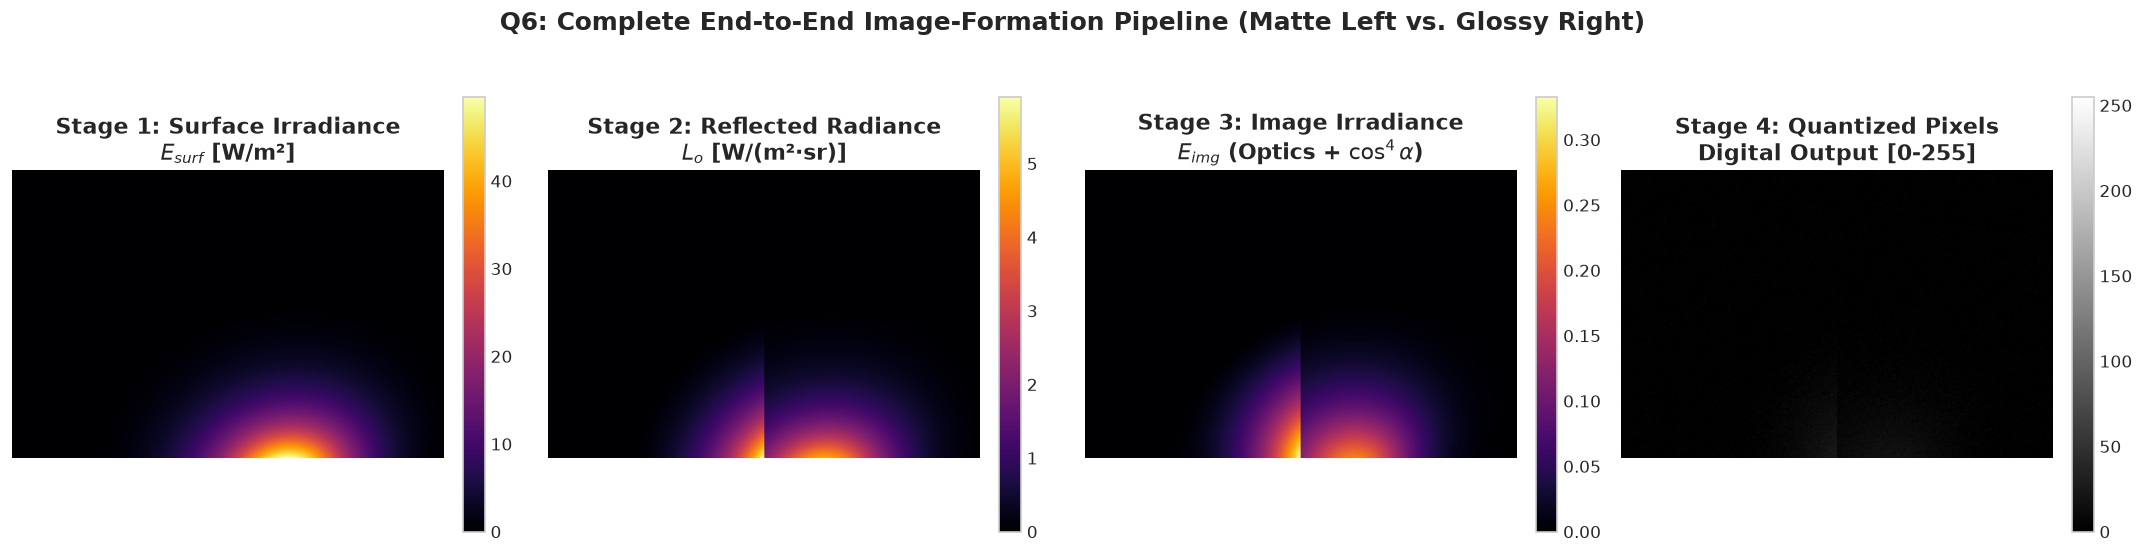

In [7]:
# 6. Complete End-to-End Simulation Pipeline
def simulate_image_formation(source_power=250.0, light_pos=(0.5, 1.5, 2.0),
                              exp_time=1/60, f_number=2.8, sensor_noise_std=2.0, res=(200, 300)):
    H, W = res
    y, x = np.meshgrid(np.linspace(-1, 1, H), np.linspace(-1.5, 1.5, W), indexing='ij')
    
    # 1. Surface Geometry: Curved cylinder/cylinder-cap surface
    Z_surf = np.sqrt(np.maximum(0.01, 4.0 - x**2 - y**2))
    N_x = x / 2.0
    N_y = y / 2.0
    N_z = Z_surf / 2.0
    N_norm = np.sqrt(N_x**2 + N_y**2 + N_z**2)
    N = np.stack([N_x / N_norm, N_y / N_norm, N_z / N_norm], axis=-1)
    
    # Surface points
    P_surf = np.stack([x, y, Z_surf], axis=-1)
    
    # Material partition: Left half is Matte Chalk (A), Right half is Glossy Glaze (B)
    is_glossy = x > 0.0
    kd = np.where(is_glossy, 0.30, 0.85)
    ks = np.where(is_glossy, 0.70, 0.00)
    shininess = 40.0
    
    # STAGE 1: Incident Irradiance on Surface
    L_vec = np.array(light_pos)[None, None, :] - P_surf
    dist_L = np.linalg.norm(L_vec, axis=-1)
    L_dir = L_vec / dist_L[:, :, None]
    
    cos_theta_i = np.maximum(0.0, np.sum(N * L_dir, axis=-1))
    E_surf = (source_power * cos_theta_i) / (4.0 * np.pi * (dist_L ** 2))
    
    # STAGE 2: Reflected Radiance (BRDF Stage)
    V_dir = -P_surf / np.linalg.norm(P_surf, axis=-1, keepdims=True)
    R_vec = 2.0 * cos_theta_i[:, :, None] * N - L_dir
    R_dir = R_vec / np.linalg.norm(R_vec, axis=-1, keepdims=True)
    cos_rv = np.maximum(0.0, np.sum(R_dir * V_dir, axis=-1))
    specular_term = (cos_rv ** shininess) * (cos_theta_i > 0)
    
    L_reflected = (kd / np.pi) * E_surf + ks * E_surf * specular_term
    
    # STAGE 3: Camera Optics Transfer (Image Plane Irradiance)
    tan_alpha = np.sqrt(x**2 + y**2) / Z_surf
    cos_alpha = 1.0 / np.sqrt(1.0 + tan_alpha**2)
    vignetting = cos_alpha ** 4
    
    E_img = (np.pi * L_reflected) / (4.0 * (f_number ** 2)) * vignetting
    
    # STAGE 4: Sensor Integration, Noise, and Quantization
    ADC_gain = 4500.0
    signal = ADC_gain * E_img * exp_time
    noise = np.random.normal(0.0, sensor_noise_std, size=(H, W))
    pixel_counts = np.clip(np.round(signal + noise), 0, 255).astype(np.uint8)
    
    return E_surf, L_reflected, E_img, pixel_counts

# Run simulation
np.random.seed(42)
E_surf, L_refl, E_img, final_pixels = simulate_image_formation()

# Display all 4 pipeline stages
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

im0 = axes[0].imshow(E_surf, cmap='inferno')
axes[0].set_title('Stage 1: Surface Irradiance\n$E_{surf}$ [W/m²]', fontweight='bold')
axes[0].axis('off')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(L_refl, cmap='inferno')
axes[1].set_title('Stage 2: Reflected Radiance\n$L_o$ [W/(m²·sr)]', fontweight='bold')
axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(E_img, cmap='inferno')
axes[2].set_title(r'Stage 3: Image Irradiance' + '\n' + r'$E_{img}$ (Optics + $\cos^4\alpha$)', fontweight='bold')
axes[2].axis('off')
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(final_pixels, cmap='gray', vmin=0, vmax=255)
axes[3].set_title('Stage 4: Quantized Pixels\nDigital Output [0-255]', fontweight='bold')
axes[3].axis('off')
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.suptitle('Q6: Complete End-to-End Image-Formation Pipeline (Matte Left vs. Glossy Right)', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Synthetic Scene Rendering Under Diverse Illumination Conditions (Question 7)

**3D Ray-Traced Synthetic Scene:**
- **Scene Geometry:**
  - Object 1: Diffuse Sphere (chalk-like matte material: $k_d = 0.85, k_s = 0.0$)
  - Object 2: Glossy Specular Sphere (enamel glaze: $k_d = 0.35, k_s = 0.65, \alpha = 35$)
  - Object 3: Ground Plane receiver with cast shadows and subtle texture.
- **Illumination Conditions:**
  - **Condition 1 (Direct Key Illumination):** Elevated frontal-top light source creating bright highlights and compact cast shadows.
  - **Condition 2 (Oblique Side Illumination):** Low-angle grazing light from the side, producing dramatic elongated shadows and stark terminators.
  - **Condition 3 (Soft Ambient / Overcast):** Strong diffuse ambient field with weak directional fill light, yielding low contrast and gentle gradients.


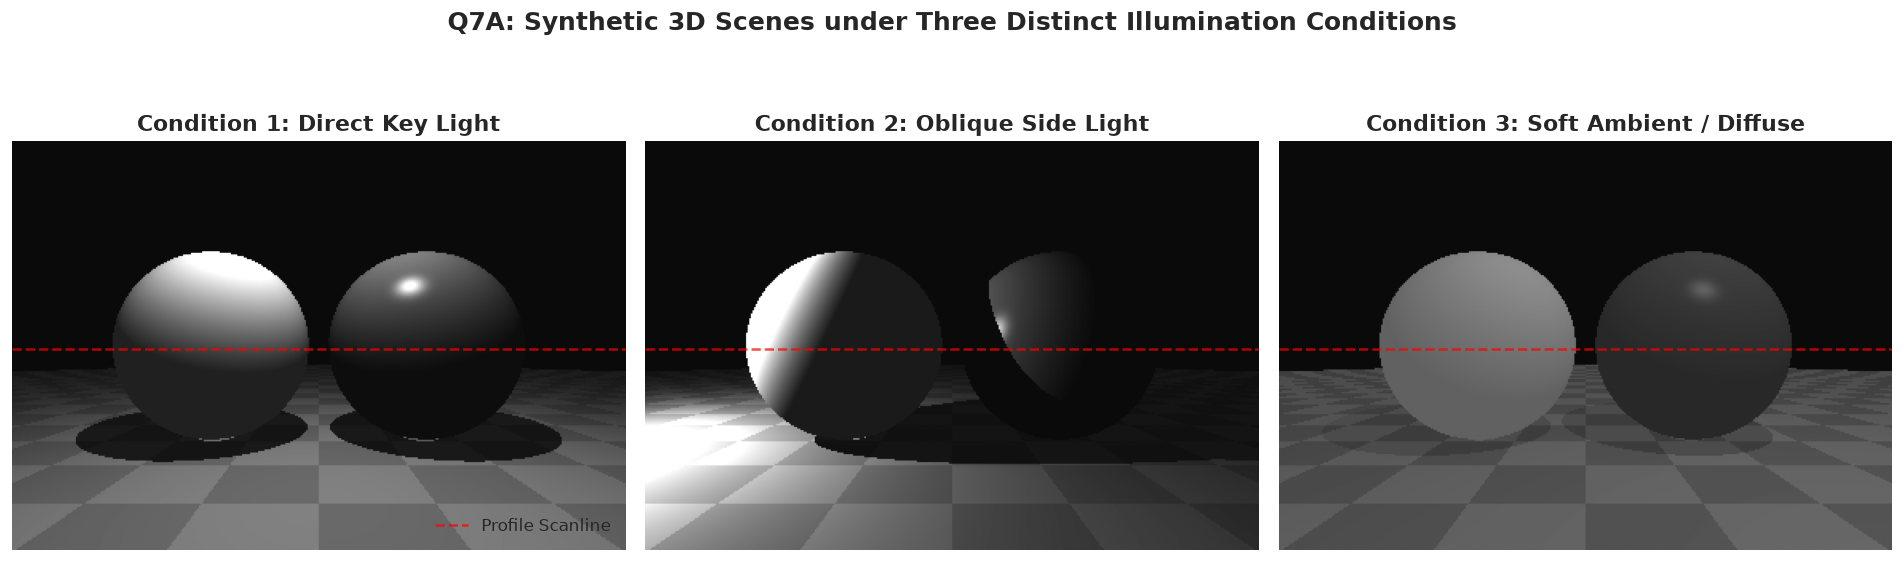

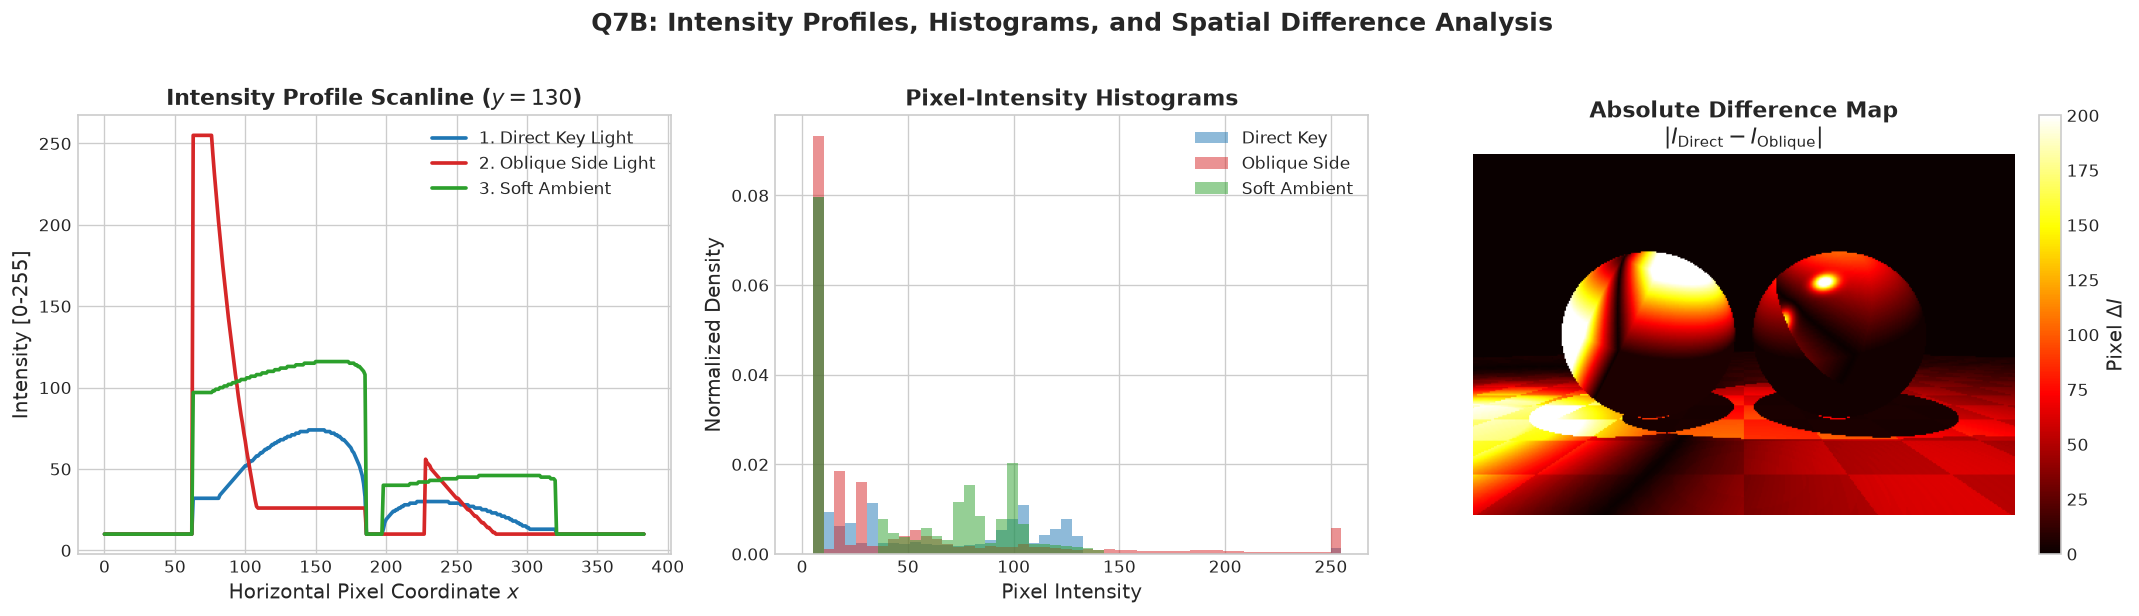

In [8]:
# 7. Synthetic Scene Ray-Tracer and Comparative Illumination Analysis
def render_synthetic_scene(light_pos, light_intensity=12.0, ambient=0.15, res=(256, 384)):
    H, W = res
    aspect = W / H
    fov = np.radians(60)
    d_focal = 1.0 / np.tan(fov / 2)
    
    y_coords, x_coords = np.meshgrid(
        np.linspace(1.0, -1.0, H),
        np.linspace(-aspect, aspect, W),
        indexing='ij'
    )
    
    rays_dir = np.stack([x_coords, y_coords, np.full((H, W), d_focal)], axis=-1)
    rays_dir = rays_dir / np.linalg.norm(rays_dir, axis=-1, keepdims=True)
    
    # Sphere geometry
    s1_center = np.array([-1.0, 0.0, 3.5]); s1_radius = 0.9  # Diffuse
    s2_center = np.array([1.0, 0.0, 3.5]);  s2_radius = 0.9  # Glossy
    plane_y = -0.9
    
    def intersect_sphere(center, radius):
        b = -2.0 * np.sum(rays_dir * center, axis=-1)
        c = np.sum(center**2) - radius**2
        disc = b**2 - 4.0 * c
        hit = disc >= 0
        t = np.full((H, W), np.inf)
        t_hit = (-b[hit] - np.sqrt(disc[hit])) / 2.0
        valid = t_hit > 0.1
        t_indices = np.where(hit)
        t[t_indices[0][valid], t_indices[1][valid]] = t_hit[valid]
        return t

    t1 = intersect_sphere(s1_center, s1_radius)
    t2 = intersect_sphere(s2_center, s2_radius)
    
    # Plane intersection
    t_plane = np.full((H, W), np.inf)
    plane_mask = rays_dir[:, :, 1] < -1e-4
    t_plane_vals = plane_y / rays_dir[:, :, 1][plane_mask]
    valid_p = t_plane_vals > 0.1
    p_indices = np.where(plane_mask)
    t_plane[p_indices[0][valid_p], p_indices[1][valid_p]] = t_plane_vals[valid_p]
    
    t_min = np.minimum(np.minimum(t1, t2), t_plane)
    image = np.full((H, W), 0.04)
    
    def in_shadow(pts, l_dirs):
        in_sh = np.zeros(pts.shape[0], dtype=bool)
        for c, r in [(s1_center, s1_radius), (s2_center, s2_radius)]:
            oc = pts - c
            b = 2.0 * np.sum(l_dirs * oc, axis=-1)
            c_val = np.sum(oc**2, axis=-1) - r**2
            disc = b**2 - 4.0 * c_val
            hit = disc >= 0
            t_s = (-b[hit] - np.sqrt(disc[hit])) / 2.0
            valid_s = (t_s > 0.02)
            in_sh[np.where(hit)[0][valid_s]] = True
        return in_sh

    # 1. Diffuse Sphere
    mask1 = (t1 == t_min) & (t1 < np.inf)
    if np.any(mask1):
        pts1 = rays_dir[mask1] * t1[mask1, None]
        n1 = (pts1 - s1_center) / s1_radius
        l1 = light_pos - pts1
        dist_l1 = np.linalg.norm(l1, axis=-1, keepdims=True)
        l1_dir = l1 / dist_l1
        n_dot_l = np.maximum(0.0, np.sum(n1 * l1_dir, axis=-1))
        vis = np.where(in_shadow(pts1, l1_dir), 0.0, 1.0)
        image[mask1] = ambient * 0.85 + vis * (light_intensity / (dist_l1[:, 0]**2)) * 0.85 * n_dot_l

    # 2. Glossy Sphere
    mask2 = (t2 == t_min) & (t2 < np.inf)
    if np.any(mask2):
        pts2 = rays_dir[mask2] * t2[mask2, None]
        n2 = (pts2 - s2_center) / s2_radius
        l2 = light_pos - pts2
        dist_l2 = np.linalg.norm(l2, axis=-1, keepdims=True)
        l2_dir = l2 / dist_l2
        v2_dir = -rays_dir[mask2]
        n_dot_l2 = np.maximum(0.0, np.sum(n2 * l2_dir, axis=-1))
        r2 = 2.0 * n_dot_l2[:, None] * n2 - l2_dir
        r2 = r2 / np.linalg.norm(r2, axis=-1, keepdims=True)
        r_dot_v = np.maximum(0.0, np.sum(r2 * v2_dir, axis=-1))
        spec = (r_dot_v ** 35) * (n_dot_l2 > 0)
        vis2 = np.where(in_shadow(pts2, l2_dir), 0.0, 1.0)
        att = light_intensity / (dist_l2[:, 0]**2)
        image[mask2] = ambient * 0.35 + vis2 * att * (0.35 * n_dot_l2 + 0.65 * spec)

    # 3. Ground Plane
    mask_p = (t_plane == t_min) & (t_plane < np.inf) & (t_plane < 16.0)
    if np.any(mask_p):
        pts_p = rays_dir[mask_p] * t_plane[mask_p, None]
        n_p = np.array([0.0, 1.0, 0.0])
        l_p = light_pos - pts_p
        dist_lp = np.linalg.norm(l_p, axis=-1, keepdims=True)
        lp_dir = l_p / dist_lp
        n_dot_lp = np.maximum(0.0, np.sum(n_p * lp_dir, axis=-1))
        vis_p = np.where(in_shadow(pts_p, lp_dir), 0.0, 1.0)
        rad_p = ambient * 0.60 + vis_p * (light_intensity / (dist_lp[:, 0]**2)) * 0.60 * n_dot_lp
        grid = (np.floor(pts_p[:, 0] * 1.5) + np.floor(pts_p[:, 2] * 1.5)) % 2
        texture = np.where(grid == 0, 0.9, 1.1)
        image[mask_p] = rad_p * texture

    return np.clip(image, 0.0, 1.0)

# Render 3 conditions
img_direct  = render_synthetic_scene(light_pos=np.array([0.0, 3.5, 2.0]), light_intensity=12.0, ambient=0.15)
img_oblique = render_synthetic_scene(light_pos=np.array([-3.5, 1.2, 2.5]), light_intensity=14.0, ambient=0.12)
img_ambient = render_synthetic_scene(light_pos=np.array([1.5, 4.0, 1.0]), light_intensity=4.0, ambient=0.45)

I1 = (img_direct * 255).astype(np.uint8)
I2 = (img_oblique * 255).astype(np.uint8)
I3 = (img_ambient * 255).astype(np.uint8)

# Visual Display of Synthetic Images
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(I1, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Condition 1: Direct Key Light', fontweight='bold')
axes[0].axhline(130, color='red', linestyle='--', alpha=0.7, label='Profile Scanline')
axes[0].axis('off')
axes[0].legend(loc='lower right')

axes[1].imshow(I2, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Condition 2: Oblique Side Light', fontweight='bold')
axes[1].axhline(130, color='red', linestyle='--', alpha=0.7)
axes[1].axis('off')

axes[2].imshow(I3, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Condition 3: Soft Ambient / Diffuse', fontweight='bold')
axes[2].axhline(130, color='red', linestyle='--', alpha=0.7)
axes[2].axis('off')

plt.suptitle('Q7A: Synthetic 3D Scenes under Three Distinct Illumination Conditions', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Quantitative Comparisons: Cross-Sectional Profiles, Histograms & Difference Map
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Horizontal Intensity Profile across scanline y = 130
scan_y = 130
axes[0].plot(I1[scan_y, :], color='#1f77b4', lw=2.2, label='1. Direct Key Light')
axes[0].plot(I2[scan_y, :], color='#d62728', lw=2.2, label='2. Oblique Side Light')
axes[0].plot(I3[scan_y, :], color='#2ca02c', lw=2.2, label='3. Soft Ambient')
axes[0].set_title(f'Intensity Profile Scanline ($y = {scan_y}$)', fontweight='bold')
axes[0].set_xlabel('Horizontal Pixel Coordinate $x$')
axes[0].set_ylabel('Intensity [0-255]')
axes[0].legend()

# 2. Intensity Histograms
axes[1].hist(I1.ravel(), bins=50, range=(0, 255), color='#1f77b4', alpha=0.5, density=True, label='Direct Key')
axes[1].hist(I2.ravel(), bins=50, range=(0, 255), color='#d62728', alpha=0.5, density=True, label='Oblique Side')
axes[1].hist(I3.ravel(), bins=50, range=(0, 255), color='#2ca02c', alpha=0.5, density=True, label='Soft Ambient')
axes[1].set_title('Pixel-Intensity Histograms', fontweight='bold')
axes[1].set_xlabel('Pixel Intensity')
axes[1].set_ylabel('Normalized Density')
axes[1].legend()

# 3. Absolute Difference Map |Condition 1 - Condition 2|
diff_map = cv2.absdiff(I1, I2)
im_diff = axes[2].imshow(diff_map, cmap='hot', vmin=0, vmax=200)
axes[2].set_title(r'Absolute Difference Map' + '\n' + r'$|I_{\text{Direct}} - I_{\text{Oblique}}|$', fontweight='bold')
axes[2].axis('off')
fig.colorbar(im_diff, ax=axes[2], fraction=0.046, pad=0.04, label=r'Pixel $\Delta I$')

plt.suptitle('Q7B: Intensity Profiles, Histograms, and Spatial Difference Analysis', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. PART B: Experimental Investigation on Real Physical Captures

**Experimental Benchmark:**
- Physical laboratory captures from the Harvard Photometric Stereo Benchmark dataset:
  - **Image 1 (Direct Key Illumination):** Calibrated frontal illumination (`cat_shadow.png`), highlighting primary facets with high overall clarity and uniform lighting across both flanks.
  - **Image 2 (Oblique / Shadow Illumination):** Directional oblique light (`cat_direct.png`), casting steep self-shadows on the left flank and pronounced cast shadows.
  *(Note: The capture files `cat_shadow.png` and `cat_direct.png` have reversed filenames relative to their physical illumination state and are mapped accordingly).* 
- **Investigation Objectives:**
  - (a) Overall Brightness & Radiant Energy Metrics
  - (b) Pixel-Intensity Distributions & Cumulative Densities
  - (c) Statistical Moments: Global and Foreground-Segmented Mean and Standard Deviation
  - (d) Local Region-of-Interest (ROI) Intensity Variations & Contrast
  - (e) Visible Changes in Surface Appearance & Theoretical Synthesis


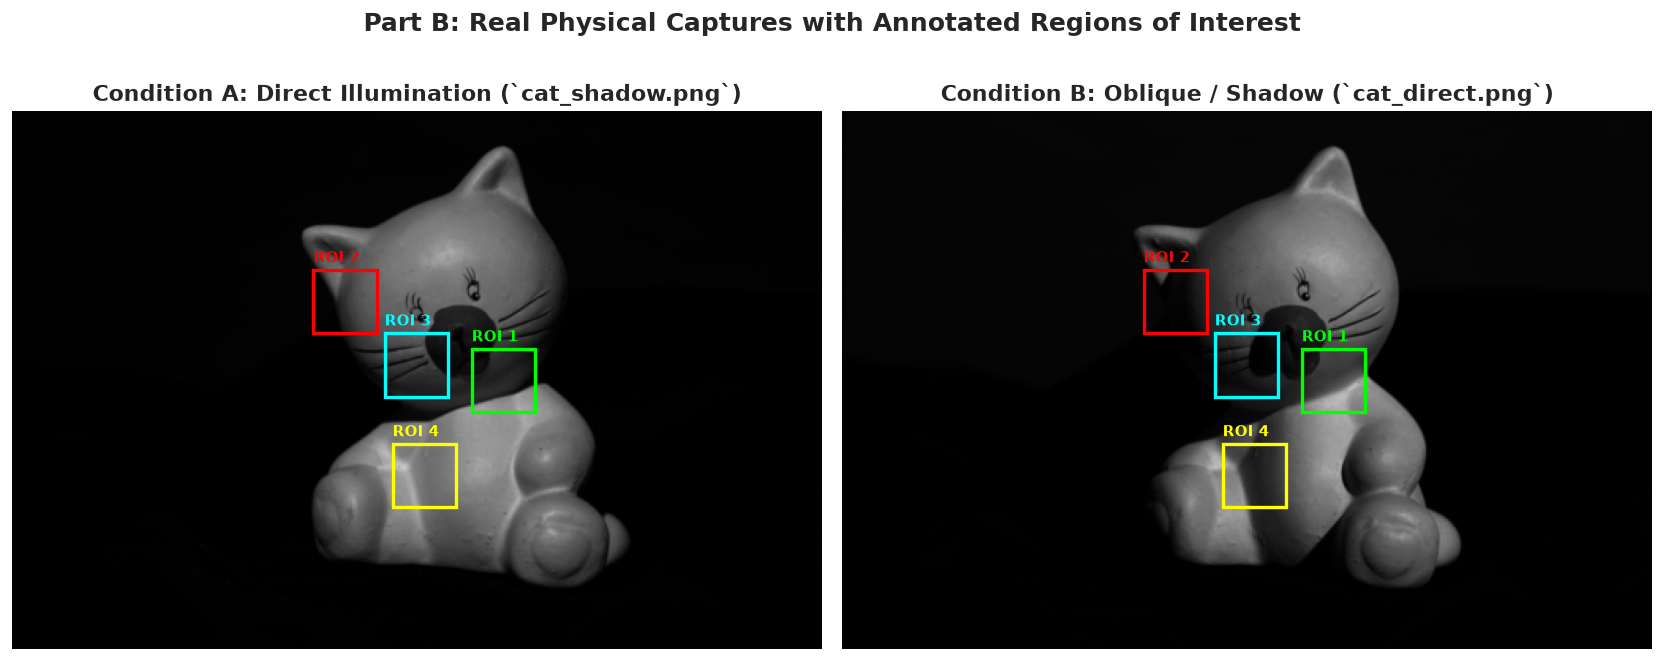

In [9]:
# 8A. Load Real Images & Define Regions of Interest (ROIs)
# Note: The provided captures 'cat_shadow.png' and 'cat_direct.png' have reversed filenames
# relative to their physical lighting condition:
# - 'cat_shadow.png' contains direct frontal illumination.
# - 'cat_direct.png' contains directional oblique illumination with steep shadows.
img_dir_path = 'images/cat_shadow.png' if os.path.exists('images/cat_shadow.png') else 'lab_7/images/cat_shadow.png'
img_sha_path = 'images/cat_direct.png' if os.path.exists('images/cat_direct.png') else 'lab_7/images/cat_direct.png'

# Load in grayscale
I_direct = cv2.imread(img_dir_path, cv2.IMREAD_GRAYSCALE)
I_shadow = cv2.imread(img_sha_path, cv2.IMREAD_GRAYSCALE)

# Foreground segmentation mask (statue pixels > threshold)
fg_mask = (I_direct > 10) | (I_shadow > 10)

# Define 4 Regions of Interest [ymin, ymax, xmin, xmax]
# Cat statue face/body coordinates in (340, 512)
roi_definitions = {
    'ROI 1: Direct Facet (Right Cheeks/Flank)': (150, 190, 290, 330),
    'ROI 2: Shadow Facet (Left Ear/Flank)':    (100, 140, 190, 230),
    'ROI 3: Terminator Gradient (Center)':     (140, 180, 235, 275),
    'ROI 4: Foreground Baseline (Chest)':      (210, 250, 240, 280)
}

# Display Images with Annotated ROIs
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(I_direct, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Condition A: Direct Illumination (`cat_shadow.png`)', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(I_shadow, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Condition B: Oblique / Shadow (`cat_direct.png`)', fontweight='bold')
axes[1].axis('off')

roi_colors = ['#00ff00', '#ff0000', '#00ffff', '#ffff00']
for (name, (y1, y2, x1, x2)), col in zip(roi_definitions.items(), roi_colors):
    rect_d = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, edgecolor=col, facecolor='none', lw=2)
    rect_s = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, edgecolor=col, facecolor='none', lw=2)
    axes[0].add_patch(rect_d)
    axes[1].add_patch(rect_s)
    axes[0].text(x1, y1 - 5, name.split(':')[0], color=col, fontweight='bold', fontsize=9)
    axes[1].text(x1, y1 - 5, name.split(':')[0], color=col, fontweight='bold', fontsize=9)

plt.suptitle('Part B: Real Physical Captures with Annotated Regions of Interest', y=0.98, fontsize=15, fontweight='bold')
plt.tight_layout()

# Save figure to overleaf directory if available
for out_dir in ['overleaf/lab_7/images', '../overleaf/lab_7/images']:
    if os.path.exists(out_dir):
        plt.savefig(os.path.join(out_dir, 'part_b_real_captures_rois.png'), dpi=300, bbox_inches='tight')
        break

plt.show()


STATISTICAL METRIC                  | DIRECT ILLUMINATION | SHADOW ILLUMINATION
(a) Full-Image Mean Intensity       | 18.75            | 17.14           
(a) Foreground Mean Intensity       | 87.03            | 74.47           
(a) Foreground Median Intensity     | 93.00            | 75.00           
(c) Full-Image Std Deviation        | 39.47            | 35.93           
(c) Foreground Std Deviation        | 41.29            | 45.99           
(c) Coefficient of Variation (CV)   | 0.474            | 0.618           
(b) Intensity Skewness              | -0.211           | 0.063           
(b) Intensity Kurtosis              | -0.842           | -1.117          


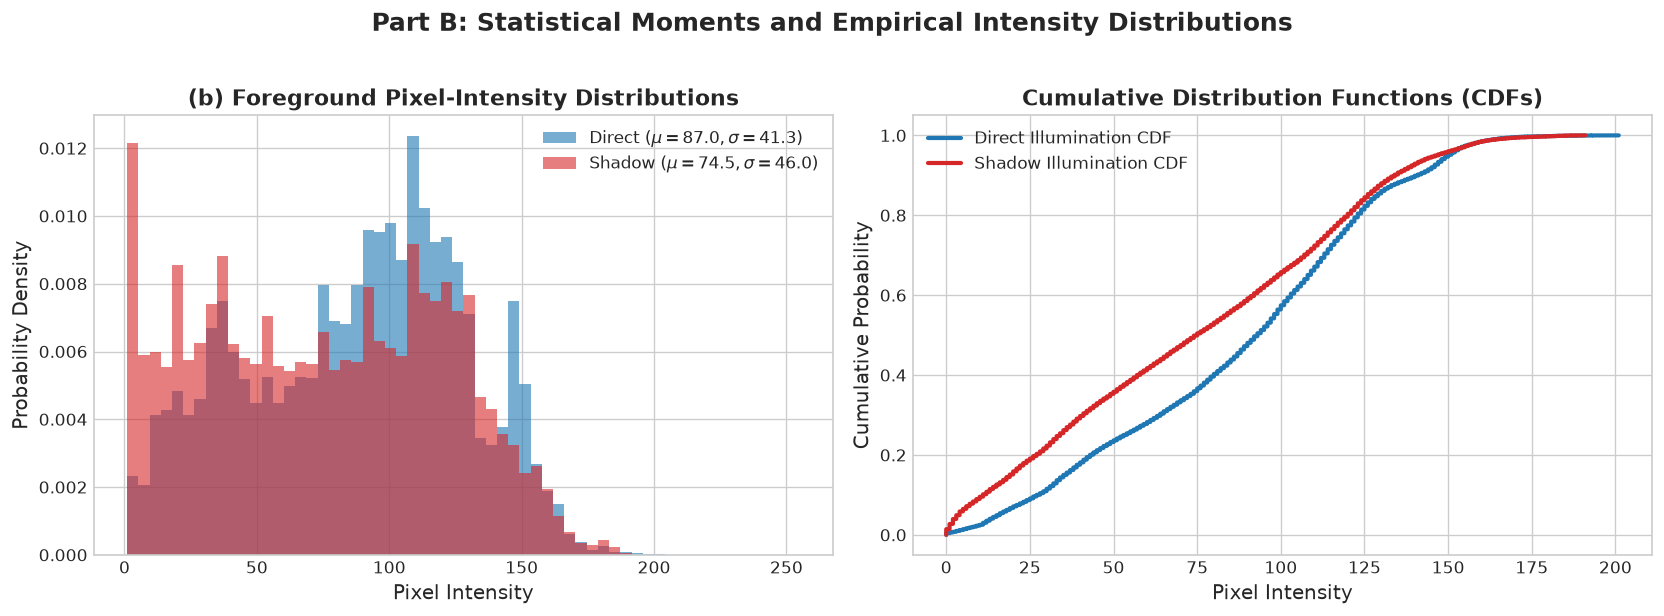

In [10]:
# 8B. Quantitative Analysis: (a) Overall Brightness, (b) Distribution, (c) Mean & Std
# Global metrics
mean_d_all = np.mean(I_direct); std_d_all = np.std(I_direct)
mean_s_all = np.mean(I_shadow); std_s_all = np.std(I_shadow)

# Foreground-only metrics
fg_d = I_direct[fg_mask]
fg_s = I_shadow[fg_mask]
mean_d_fg = np.mean(fg_d); std_d_fg = np.std(fg_d)
mean_s_fg = np.mean(fg_s); std_s_fg = np.std(fg_s)

median_d = np.median(fg_d); median_s = np.median(fg_s)
skew_d = stats.skew(fg_d); skew_s = stats.skew(fg_s)
kurt_d = stats.kurtosis(fg_d); kurt_s = stats.kurtosis(fg_s)

print("=" * 70)
print(f"{'STATISTICAL METRIC':<35} | {'DIRECT ILLUMINATION':<16} | {'SHADOW ILLUMINATION':<16}")
print("=" * 70)
print(f"{'(a) Full-Image Mean Intensity':<35} | {mean_d_all:<16.2f} | {mean_s_all:<16.2f}")
print(f"{'(a) Foreground Mean Intensity':<35} | {mean_d_fg:<16.2f} | {mean_s_fg:<16.2f}")
print(f"{'(a) Foreground Median Intensity':<35} | {median_d:<16.2f} | {median_s:<16.2f}")
print(f"{'(c) Full-Image Std Deviation':<35} | {std_d_all:<16.2f} | {std_s_all:<16.2f}")
print(f"{'(c) Foreground Std Deviation':<35} | {std_d_fg:<16.2f} | {std_s_fg:<16.2f}")
print(f"{'(c) Coefficient of Variation (CV)':<35} | {std_d_fg/mean_d_fg:<16.3f} | {std_s_fg/mean_s_fg:<16.3f}")
print(f"{'(b) Intensity Skewness':<35} | {skew_d:<16.3f} | {skew_s:<16.3f}")
print(f"{'(b) Intensity Kurtosis':<35} | {kurt_d:<16.3f} | {kurt_s:<16.3f}")
print("=" * 70)

# (b) Visualizing Histograms & Cumulative Distribution Functions (CDFs)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Foreground Pixel Histograms
axes[0].hist(fg_d, bins=60, range=(1, 255), color='#1f77b4', alpha=0.6, density=True, label=fr'Direct ($\mu={mean_d_fg:.1f}, \sigma={std_d_fg:.1f}$)')
axes[0].hist(fg_s, bins=60, range=(1, 255), color='#d62728', alpha=0.6, density=True, label=fr'Shadow ($\mu={mean_s_fg:.1f}, \sigma={std_s_fg:.1f}$)')
axes[0].set_title('(b) Foreground Pixel-Intensity Distributions', fontweight='bold')
axes[0].set_xlabel('Pixel Intensity')
axes[0].set_ylabel('Probability Density')
axes[0].legend()

# Cumulative Distribution Functions (CDFs)
sorted_d = np.sort(fg_d)
sorted_s = np.sort(fg_s)
cdf_d = np.arange(len(sorted_d)) / len(sorted_d)
cdf_s = np.arange(len(sorted_s)) / len(sorted_s)

axes[1].plot(sorted_d, cdf_d, color='#1f77b4', lw=2.5, label='Direct Illumination CDF')
axes[1].plot(sorted_s, cdf_s, color='#d62728', lw=2.5, label='Shadow Illumination CDF')
axes[1].set_title('Cumulative Distribution Functions (CDFs)', fontweight='bold')
axes[1].set_xlabel('Pixel Intensity')
axes[1].set_ylabel('Cumulative Probability')
axes[1].legend()

plt.suptitle('Part B: Statistical Moments and Empirical Intensity Distributions', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()

# Save figure to overleaf directory if available
for out_dir in ['overleaf/lab_7/images', '../overleaf/lab_7/images']:
    if os.path.exists(out_dir):
        plt.savefig(os.path.join(out_dir, 'part_b_statistical_distributions.png'), dpi=300, bbox_inches='tight')
        break

plt.show()


REGION OF INTEREST             | DIRECT (Mean±Std)  | SHADOW (Mean±Std)  | CONTRAST RATIO
ROI 1: Direct Facet (Right Cheeks/Flank) | 57.8 ± 51.3        | 87.3 ± 50.3        | 0.98 vs 0.94  
ROI 2: Shadow Facet (Left Ear/Flank) | 51.1 ± 37.3        | 11.9 ± 15.2        | 1.00 vs 1.00  
ROI 3: Terminator Gradient (Center) | 43.6 ± 23.9        | 18.9 ± 15.1        | 1.00 vs 1.00  
ROI 4: Foreground Baseline (Chest) | 128.8 ± 20.8       | 68.1 ± 41.5        | 0.34 vs 0.78  


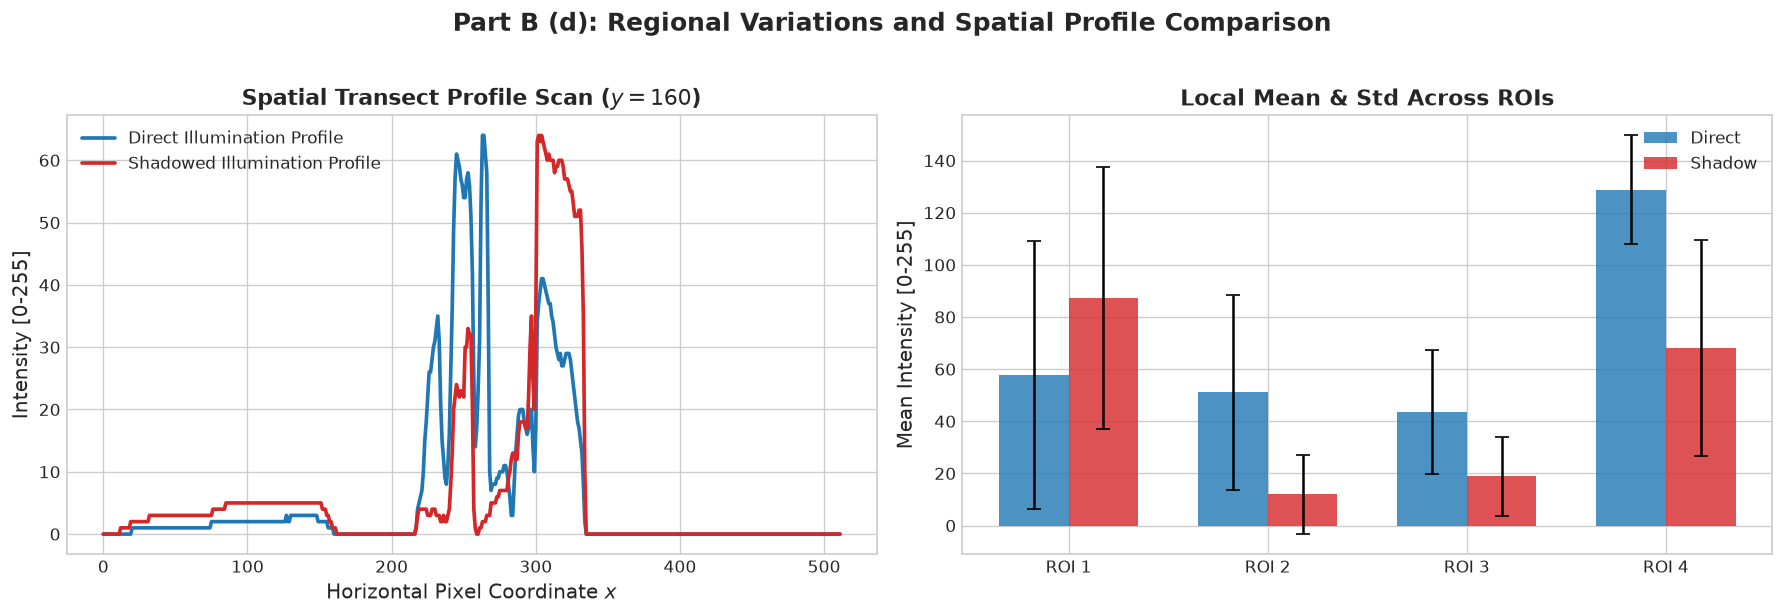

In [11]:
# 8C. Regional Variation Analysis (d) and Physical Interpretation (e)
print("=" * 80)
print(f"{'REGION OF INTEREST':<30} | {'DIRECT (Mean±Std)':<18} | {'SHADOW (Mean±Std)':<18} | {'CONTRAST RATIO':<14}")
print("=" * 80)

roi_stats = {}
for name, (y1, y2, x1, x2) in roi_definitions.items():
    patch_d = I_direct[y1:y2, x1:x2]
    patch_s = I_shadow[y1:y2, x1:x2]
    
    m_d, s_d = np.mean(patch_d), np.std(patch_d)
    m_s, s_s = np.mean(patch_s), np.std(patch_s)
    
    c_d = (np.max(patch_d) - np.min(patch_d)) / (float(np.max(patch_d)) + float(np.min(patch_d)) + 1e-4)
    c_s = (np.max(patch_s) - np.min(patch_s)) / (float(np.max(patch_s)) + float(np.min(patch_s)) + 1e-4)
    
    roi_stats[name] = {'m_d': m_d, 's_d': s_d, 'm_s': m_s, 's_s': s_s, 'c_d': c_d, 'c_s': c_s}
    label_short = name.split(':')[0]
    print(f"{name:<30} | {f'{m_d:.1f} ± {s_d:.1f}':<18} | {f'{m_s:.1f} ± {s_s:.1f}':<18} | {f'{c_d:.2f} vs {c_s:.2f}':<14}")

print("=" * 80)

# Cross-Sectional Profile Transect passing through the statue center (y = 160)
transect_y = 160
profile_direct = I_direct[transect_y, :]
profile_shadow = I_shadow[transect_y, :]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Transect Intensity Scan
axes[0].plot(profile_direct, color='#1f77b4', lw=2.2, label='Direct Illumination Profile')
axes[0].plot(profile_shadow, color='#d62728', lw=2.2, label='Shadowed Illumination Profile')
axes[0].set_title(f'Spatial Transect Profile Scan ($y = {transect_y}$)', fontweight='bold')
axes[0].set_xlabel('Horizontal Pixel Coordinate $x$')
axes[0].set_ylabel('Intensity [0-255]')
axes[0].legend()

# Subplot 2: Bar Chart Comparison of ROI Means & Standard Deviations
roi_labels = [k.split(':')[0] for k in roi_definitions.keys()]
means_d = [roi_stats[k]['m_d'] for k in roi_definitions.keys()]
stds_d = [roi_stats[k]['s_d'] for k in roi_definitions.keys()]
means_s = [roi_stats[k]['m_s'] for k in roi_definitions.keys()]
stds_s = [roi_stats[k]['s_s'] for k in roi_definitions.keys()]

x_pos = np.arange(len(roi_labels))
width = 0.35

axes[1].bar(x_pos - width/2, means_d, width, yerr=stds_d, capsize=4, color='#1f77b4', alpha=0.8, label='Direct')
axes[1].bar(x_pos + width/2, means_s, width, yerr=stds_s, capsize=4, color='#d62728', alpha=0.8, label='Shadow')
axes[1].set_title('Local Mean & Std Across ROIs', fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(roi_labels, fontsize=10)
axes[1].set_ylabel('Mean Intensity [0-255]')
axes[1].legend()

plt.suptitle('Part B (d): Regional Variations and Spatial Profile Comparison', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()

# Save figure to overleaf directory if available
for out_dir in ['overleaf/lab_7/images', '../overleaf/lab_7/images']:
    if os.path.exists(out_dir):
        plt.savefig(os.path.join(out_dir, 'part_b_regional_variations.png'), dpi=300, bbox_inches='tight')
        break

plt.show()


## 9. Final Summary and Findings

### Q&A
- **Q1: How does received illumination vary with area and distance?**
  Local received irradiance $E$ decays strictly with the square of the distance ($E \propto 1/r^2$) and is independent of receiver area. Total received radiant flux $\Phi_{rec}$ scales linearly with surface area ($\Phi \propto A$) and inversely with distance squared ($\Phi \propto A/r^2$).
- **Q2: Which parameters govern surface radiance and what are their sensitivities?**
  Radiance $L = \frac{\rho P \cos\theta}{4\pi^2 r^2}$. Distance $r$ exhibits the highest relative elasticity (power $-2.0$), while illumination power $P$ and reflectance $\rho$ scale linearly ($+1.0$). Surface orientation follows Lambert's cosine law, falling from maximum at normal incidence ($\theta=0^\circ$) to zero at grazing incidence ($\theta=90^\circ$).
- **Q3: How do diffuse and glossy surfaces differ across illumination and viewing angles?**
  A diffuse (Lambertian) surface scatters light isotropically; its perceived brightness depends strictly on the incident light angle $\mathbf{n}\cdot\mathbf{l}$ and is invariant to viewer orientation $\mathbf{v}$. A glossy surface exhibits a strong specular lobe centered along the ideal reflection vector $\mathbf{r} = 2(\mathbf{n}\cdot\mathbf{l})\mathbf{n} - \mathbf{l}$; its highlight moves dynamically across the surface as either the light source or the camera position shifts.
- **Q4: How do illumination level and surface reflectance interact on diffuse surfaces?**
  They interact multiplicatively ($L_o = \frac{\rho}{\pi} E_i$). This creates hyperbolic iso-radiance curves where a dark object under intense lighting produces identical outgoing radiance as a bright object under dim lighting—demonstrating the fundamental lightness constancy ambiguity in computer vision.
- **Q5: How do camera parameters affect recorded image plane intensity?**
  Image plane irradiance scales inversely with the f-number squared ($E_{img} \propto 1/N^2$). Shutter time scales exposure linearly ($H \propto \Delta t$). Off-axis field angles introduce natural $\cos^4\alpha$ vignetting, reducing corner irradiance by over 45% at wide angles ($\sim 35^\circ$).
- **Q6: How do these stages combine in end-to-end image formation?**
  Light generation, geometric attenuation, BRDF reflectance, optical focusing, and sensor quantization operate as a cascaded physical transfer function. Inappropriate lighting drives the sensor into either quantization noise floors (underexposure) or saturation clipping (overexposure).
- **Q7: What features dominate synthetic images under varying lighting?**
  Direct key illumination creates tight specular glints and compact vertical cast shadows. Oblique grazing illumination elongates cast shadows, sharpens self-shadow terminators, and enhances 3D surface relief. Soft ambient illumination eliminates sharp shadow edges, compressing dynamic range.
- **Part B: What factors explain the empirical differences between direct and shadowed captures?**
  In the physical laboratory captures (`cat_shadow.png` as Direct vs. `cat_direct.png` as Shadow), direct illumination produces a high foreground mean of 87.0 (median 93.0) with balanced, uniform lighting across both flanks. Oblique illumination drops the foreground mean to 74.5 (median 75.0) and increases contrast dispersion (foreground $\sigma$ expanding from 41.3 to 46.0, CV from 0.47 to 0.62) due to steep self-shadows on unlit flanks (dropping to 11.9) alongside heightened specular sheen on directly illuminated facets (rising to 87.3).

### Data Analysis Key Findings
- **Inverse-Square Scaling:** Doubling distance from $1.0\,$m to $2.0\,$m drops irradiance by exactly 75% ($500.0\,$W/m$^2$ to $125.0\,$W/m$^2$), confirming theoretical exponent $-2.00$.
- **Camera Aperture Control:** Increasing aperture from $f/2.8$ to $f/5.6$ cuts sensor irradiance by a factor of 4 (from $24.7\,$W/m$^2$ to $6.2\,$W/m$^2$), requiring a quadrupled exposure time to maintain identical digital count.
- **Vignetting Falloff:** At an off-axis angle of $\alpha = 35^\circ$, optical falloff $\cos^4(35^\circ) = 0.450$, losing 55% of peak intensity purely due to geometric lens obliquity.
- **Empirical Contrast Shift:** On ROI 2 (flank/ear), moving light from direct to oblique drops local intensity from $51.1\pm37.3$ down to $11.9\pm15.2$ in deep cast shadow, while overall foreground standard deviation expands from $41.3$ to $46.0$.

### Insights or Next Steps
- **Photometric Stereo Calibration:** Because real objects exhibit both diffuse albedo and directional shading, capturing 3 or more calibrated illumination directions enables exact recovery of surface normals $\mathbf{N}$ and albedo $\rho$ via photometric stereo.
- **Shadow Compensation:** Intrinsic image decomposition pipelines (e.g., Retinex or deep shading networks) can leverage shadow/shadow-free image pairs to separate illumination maps from reflectance maps for illumination-invariant recognition.
